# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Паскин Владислав Романович**

**Файлы данных: data/clients.csv, data/transactions.csv**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
clients = pd.read_csv(f"data/{RAW_CLIENTS}")
txn = pd.read_csv(f"data/{RAW_TXN}", encoding="cp1251", delimiter=";", decimal=",")


print("clients.info():")
print()
print(clients.info())

print('\n')

print("txn.info():")
print()
print(txn.info())

clients.info():

<class 'pandas.DataFrame'>
RangeIndex: 5667 entries, 0 to 5666
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5667 non-null   str    
 1   birth_date          5667 non-null   str    
 2   gender              5667 non-null   str    
 3   city                5667 non-null   str    
 4   segment             5667 non-null   str    
 5   loyalty_tier        5667 non-null   str    
 6   card_type           5667 non-null   str    
 7   registration_date   5667 non-null   str    
 8   card_open_date      5667 non-null   str    
 9   income_source       5667 non-null   str    
 10  monthly_income      5110 non-null   float64
 11  has_mobile_app      5667 non-null   str    
 12  app_last_login      3450 non-null   str    
 13  satisfaction_score  2347 non-null   float64
 14  branch_code         5667 non-null   int64  
 15  marketing_opt_in    5667 non-null   str    
dtype

In [3]:
print(txn.head())
print()
print(clients.head())
print()
print(clients.isna().sum())
print()
print(txn.isna().sum())

   txn_id client_id         txn_datetime   amount currency             category  mcc_code      channel   status
0  990083   C002133  2023-11-22 16:23:11  1985.50      RUB     кафе и рестораны      5812        Карта  успешно
1  990077   C005855  2023-11-25 14:33:13   146.65      RUB     Связь и интернет      4814        Карта  успешно
2  990145   C001595  2023-12-05 12:36:22  4117.21      RUB             Продукты      5411  Онлайн-банк  успешно
3  990210   C002188  2023-12-07 17:23:04   881.69      RUB                  АЗС      5541        Карта  успешно
4  990168   C000948  2023-12-28 23:18:53  1631.50      RUB  Развлечения и досуг      7832  Онлайн-банк  успешно

  client_id  birth_date gender             city     segment loyalty_tier  card_type registration_date card_open_date            income_source  monthly_income  \
0   C001865  1983-11-19      Ж      Новосибирск  Зарплатный      Серебро  Кредитная        15.04.2021     17.03.2025   Зарплата в нашем банке             NaN   
1   C

In [4]:
# categories
print(clients['gender'].value_counts())
print()
print(clients['city'].value_counts())
print()
print(clients['segment'].value_counts())
print()
print(clients['loyalty_tier'].value_counts())
print()
print(clients['card_type'].value_counts())
print()
print(clients['income_source'].value_counts())
print()
print(txn['currency'].value_counts())
print()
print(txn['category'].value_counts())
print()
print(txn['channel'].value_counts())
print()
print(txn['status'].value_counts())
print()

# bool
print(clients['has_mobile_app'].value_counts())
print()
print(clients['marketing_opt_in'].value_counts())
print()

gender
Ж    2858
М    2809
Name: count, dtype: int64

city
Москва                1075
Казань                 743
Санкт-Петербург        639
Новосибирск            551
Нижний Новгород        523
Екатеринбург           517
казань                 216
 москва                206
г. Москва              183
Н. Новгород            171
МОСКВА                 170
г. Новосибирск         143
г.Екатеринбург         117
г. Санкт-Петербург     113
Санкт Петербург        112
СПб                    105
ЕКАТЕРИНБУРГ            83
Name: count, dtype: int64

segment
Массовый       2936
Зарплатный     1559
Премиальный     929
Private         243
Name: count, dtype: int64

loyalty_tier
Базовый    2942
Серебро    1486
Золото      941
Платина     298
Name: count, dtype: int64

card_type
Дебетовая      3946
Кредитная      1240
Премиальная     481
Name: count, dtype: int64

income_source
Зарплата в нашем банке     2554
Не указан                  1598
Зарплата в другом банке    1515
Name: count, dtype: int64

cu

**clients.city**, clients.segment, clients.loyalty_tier, clients.card_type, txn.currency, **txn.category**, txn.channel, txn.status - все это категории, в выделенных содержатся ненормализованные значения - нормализовать на препроцессинге

clients.branch_code, txn.txn_id, txn.mcc_code прочитались как int64, но это коды - у branch_code при этом теряются ведущие нули (00761 -> 761), поэтому читаем их строкой

5 разных колонок с датой/временем:
 1. txn.txn_datetime 
 2. clients.birth_date 
 3. clients.registration_date 
 4. clients.card_open_date 
 5. clients.app_last_login

имеют 4 разных формата: 
  1. yyyy-mm-dd hh:mm:ss (txn_datetime, часть строк без времени)
  2. yyyy-mm-dd(birth_date) 
  3. dd.mm.yyyy(registration_date и card_open_date) 
  4. yyyy-mm (app_last_login) 

In [5]:
TXN_DTYPES = {
    'txn_id': 'string',
    'client_id': 'string',
    'amount': 'float64',
    'currency': 'category',
    'category': 'category',
    'mcc_code': 'string',
    'channel': 'category',
    'status': 'category' 
}

CLIENTS_DTYPES = {
    'client_id': 'string',
    'gender': 'category',
    'segment': 'category',
    'loyalty_tier': pd.CategoricalDtype(['Базовый', 'Серебро', 'Золото', 'Платина'], ordered=True),
    'card_type': 'category',
    'income_source': 'category',
    'has_mobile_app': 'bool',
    'satisfaction_score': 'float64',
    'branch_code': 'string',
    'marketing_opt_in': 'bool'
}

clients = pd.read_csv(f"data/{RAW_CLIENTS}", dtype=CLIENTS_DTYPES, true_values=['Да'], false_values=['Нет'])
txn = pd.read_csv(f"data/{RAW_TXN}", encoding="cp1251", delimiter=";", decimal=",", dtype=TXN_DTYPES)

for col in ['birth_date', 'registration_date', 'card_open_date', 'app_last_login']:
    print(col, clients[col].str.replace(r'\d', '9', regex=True).value_counts(dropna=False).to_dict())

clients['birth_date'] = pd.to_datetime(clients['birth_date'], errors='raise', format='%Y-%m-%d')
clients['registration_date'] = pd.to_datetime(clients['registration_date'], errors='raise', format='%d.%m.%Y')
clients['card_open_date'] = pd.to_datetime(clients['card_open_date'], errors='raise', format='%d.%m.%Y')
clients['app_last_login'] = pd.to_datetime(clients['app_last_login'], errors='raise', format='%Y-%m').dt.to_period('M')

birth_date {'9999-99-99': 5667}
registration_date {'99.99.9999': 5667}
card_open_date {'99.99.9999': 5667}
app_last_login {'9999-99': 3450, nan: 2217}


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [6]:
# объёмы
print("clients shape:", clients.shape)
print("txn shape:", txn.shape)

# ключи
print(f"unique values in clients.client_id: {clients['client_id'].nunique()}, NA count: {clients['client_id'].isna().sum()}")
print(f"unique values in txn.txn_id: {txn['txn_id'].nunique()}, NA count: {txn['txn_id'].isna().sum()}")

clients shape: (5667, 16)
txn shape: (616795, 9)
unique values in clients.client_id: 5612, NA count: 0
unique values in txn.txn_id: 615295, NA count: 0


единица наблюдения: clients - 1 строка = 1 клиент на 30.06.2025, txn - 1 строка = 1 операция (включая отклоненные и возвраты)

ключи таблиц дублируются

In [7]:
# доля дублированных ключей (% от общего кол-ва строк)
total = clients.shape[0]
dup_count = total - clients['client_id'].nunique()
print(f"clients duplicate key rate (% of total): {(dup_count / total) * 100:.3f}, or {dup_count} of {total}")

total = txn.shape[0]
dup_count = total - txn['txn_id'].nunique()
print(f"txn duplicate key rate (% of total): {(dup_count / total) * 100:.3f}, or {dup_count} of {total}")

clients duplicate key rate (% of total): 0.971, or 55 of 5667
txn duplicate key rate (% of total): 0.243, or 1500 of 616795


In [8]:
# типы
print(clients.info())
print()
print(txn.info())

<class 'pandas.DataFrame'>
RangeIndex: 5667 entries, 0 to 5666
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5667 non-null   string        
 1   birth_date          5667 non-null   datetime64[us]
 2   gender              5667 non-null   category      
 3   city                5667 non-null   str           
 4   segment             5667 non-null   category      
 5   loyalty_tier        5667 non-null   category      
 6   card_type           5667 non-null   category      
 7   registration_date   5667 non-null   datetime64[us]
 8   card_open_date      5667 non-null   datetime64[us]
 9   income_source       5667 non-null   category      
 10  monthly_income      5110 non-null   float64       
 11  has_mobile_app      5667 non-null   bool          
 12  app_last_login      3450 non-null   period[M]     
 13  satisfaction_score  2347 non-null   float64       
 14  bra

```txn_datetime``` содержит внутри себя разные форматы значений;

In [9]:
# форматы дат в txn.txn_datetime
to_be_parsed = pd.to_datetime(txn['txn_datetime'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
other = to_be_parsed.isna() & txn['txn_datetime'].notna()

print(f"YYYY-MM-DD HH:MM:SS format matches {to_be_parsed.notna().sum()} of total {txn.shape[0]}")
print(f"\"other\" format found in {other.sum()} of total {txn.shape[0]} (rate {(other.sum() / txn.shape[0])*100:.3f}%)")

YYYY-MM-DD HH:MM:SS format matches 567172 of total 616795
"other" format found in 49623 of total 616795 (rate 8.045%)


In [10]:
# форматов, отличающихся от YYYY-MM-DD HH:MM:SS
print(txn.loc[other, "txn_datetime"].str.replace(r"\d", "9", regex=True).value_counts())

txn_datetime
9999-99-99    49623
Name: count, dtype: int64


т.е. в ```txn.txn_datetime``` всего 2 формата: **с HH:MM:SS** и **без**. Случайна ли потеря времени и что с ней делать - в 3.1

In [11]:
# даты, выходящие за заявленный период
month = txn['txn_datetime'].str[:7]
out_of_period = (month < '2024-01') | (month > '2025-06')
print(f"transactions out of period: {out_of_period.sum()} of total {txn.shape[0]} (rate {(out_of_period.sum() / txn.shape[0])*100:.3f}%)")
print(f"before 2024-01: {(month < '2024-01').sum()}")
print(f"after 2025-06: {(month > '2025-06').sum()}")

transactions out of period: 84 of total 616795 (rate 0.014%)
before 2024-01: 5
after 2025-06: 79


84 транзакции (0.014% из 616795: 5 до 2024-01, 79 после 2025-06) находятся вне заявленного периода охвата данных, необходимо будет их удалить на препроцессинге, т.к. они не относятся ни к охвату данных, ни к оцениваемому периоду

### 2.2. Дубли

In [12]:
# дубликаты ключей
dup_key = clients["client_id"].duplicated(keep=False)
full = clients.duplicated(keep=False)
print(f"clients duplicated keys: {clients.loc[dup_key, 'client_id'].nunique()}")
print(f"clients rows with duplicated key: {dup_key.sum()}")
print(f"clients full copy rows: {(dup_key & full).sum()}")
print(f"clients conflicts: {(dup_key & ~full).sum()}")

dup_key = txn["txn_id"].duplicated(keep=False)
full = txn.duplicated(keep=False)
print(f"txn duplicated keys: {txn.loc[dup_key, 'txn_id'].nunique()}")
print(f"txn rows with duplicated key: {dup_key.sum()}")
print(f"txn full copy rows: {(dup_key & full).sum()}")
print(f"txn conflicts: {(dup_key & ~full).sum()}")

clients duplicated keys: 55


clients rows with duplicated key: 110
clients full copy rows: 80
clients conflicts: 30
txn duplicated keys: 1500
txn rows with duplicated key: 3000
txn full copy rows: 2602
txn conflicts: 398


In [13]:
# поля, по которым расхождения с одинаковыми клчюами
conf = clients[clients['client_id'].duplicated(keep=False) & ~clients.duplicated(keep=False)]
diff = (conf.groupby('client_id').nunique(dropna=False) > 1).sum()
print(f"clients conflict fileds with same key")
print(diff[diff > 0].sort_values(ascending=False), '\n')

conf = txn[txn['txn_id'].duplicated(keep=False) & ~txn.duplicated(keep=False)]
diff = (conf.groupby('txn_id').nunique(dropna=False) > 1).sum()
print(f"txn conflict fileds with same key")
print(diff[diff > 0].sort_values())

clients conflict fileds with same key
segment    13
city       12
dtype: int64 

txn conflict fileds with same key
txn_datetime    199
dtype: int64


```clients```: 55 client_id встречаются дважды (110 строк, 55 лишних из 5667, 0.971%). Из 55 ключей 40 - полные копии, 15 - конфликты: у 10 расходятся и segment, и city, у 3 только segment, у 2 только city.

```txn```: 1500 txn_id встречаются дважды (3000 строк, 1500 лишних из 616795, 0.243%). Из 1500 ключей 1301 - полные копии, 199 - конфликты, у всех расходится только txn_datetime.

### 2.3. Соответствие данных описанию полей из задания

категориальные и булевы колонки частично подтверждены ```value_counts()``` из 1. Загрузка сырых данных, ячейка 3. Они реально категориальные и булевы; содержат в себе значения, по смыслу сходящиеся с описанием (связи пар ```app_last_login``` и ```has_mobile_app```, ```mcc_code``` и ```category``` проверены ниже).

```client_id``` и ```txn_id``` - не уникальные идентификаторы, содержатся дубликаты

In [14]:
# дни рождения
print(clients['birth_date'].describe().drop('mean'))

count                   5667
min      1936-07-24 00:00:00
25%      1963-05-07 00:00:00
50%      1973-08-24 00:00:00
75%      1982-05-11 00:00:00
max      2001-11-19 00:00:00
Name: birth_date, dtype: object


5 667 дат без пропусков, диапазон 1936.07.24 - 2001.11.19, медиана 1973.08.24

In [15]:
val_counts = clients["satisfaction_score"].value_counts(dropna=False)
print(val_counts.sort_index())
print(f"NaN rate (% of total): {(val_counts[np.nan] / clients.shape[0] * 100):.3f}%")

satisfaction_score
1.0     300
2.0     457
3.0     497
4.0     449
5.0     644
NaN    3320
Name: count, dtype: int64
NaN rate (% of total): 58.585%


оценки удовлетворяют описанию, но есть 3320 пропусков (58.585% от всех (5667)), "не проходил опрос" - наиболее вероятная причина

In [16]:
d = clients["monthly_income"].describe()
print(d.to_string(float_format=lambda v: f"{v:,.2f}".replace(",", " ")))

negative_income = (clients['monthly_income'] < 0).sum()
print(f"income < 0: {negative_income}")
print(f"positive income < 1000: {(clients['monthly_income'] < 1000).sum() - negative_income}")
print(f"positive income < 10000: {(clients['monthly_income'] < 10000).sum() - negative_income}")

count       5 110.00
mean       94 734.83
std        82 987.14
min          -999.00
25%        51 725.00
50%        72 750.00
75%       108 575.00
max     1 018 800.00
income < 0: 53
positive income < 1000: 173
positive income < 10000: 173


226 строк с **некорректным** доходом: 53 из них (23.451%) имеют отрицательный доход, 173 (76.549%) - доход менее 1000. Вторые похожи на измерения в тысячах, т.к. в диапазоне [1000; 10000) нет ни одного значения

доля строк с некорректным доходом от всех (5667) составляет 3.988% 

In [17]:
# даты регистраций и выдач карт, с учетом состояния на 30.06.2025
snap = pd.Timestamp("2025-06-30")

for col in ["registration_date", "card_open_date"]:
    s = clients[col]
    print(f"{col}: min {s.min().date()} | max {s.max().date()} | NaN {s.isna().sum()}")
    print(f"later than 30.06.2025: {(s > snap).sum()}")
print()

print("card opened before registration:", (clients["card_open_date"] < clients["registration_date"]).sum())

registration_date: min 2010-02-11 | max 2025-04-02 | NaN 0
later than 30.06.2025: 0
card_open_date: min 2016-01-02 | max 2025-05-16 | NaN 0
later than 30.06.2025: 0

card opened before registration: 0


нарушений нет (0 из 5667)

In [18]:
# app_last_login - период
ll = clients['app_last_login']
print(f"min {ll.min()} | max {ll.max()} | NaN {ll.isna().sum()}")
print("later than 2025-06:", (ll > snap.to_period("M")).sum())
print(pd.crosstab(clients["has_mobile_app"], ll.notna()))
print(clients['has_mobile_app'].value_counts())

min 2024-01 | max 2025-06 | NaN 2217
later than 2025-06: 0
app_last_login  False  True 
has_mobile_app              
False            2217      0
True                0   3450
has_mobile_app
True     3450
False    2217
Name: count, dtype: int64


```app_last_login``` - месяц последнего входа - 3 450 заполнено, 2 217 NaN, диапазон 2024.01 - 2025.06, входов позже 2025.06 нет; пропуски ровно у клиентов без приложения (2 217 против 3 450, без исключений) 

In [19]:
# branch_code - код отделения: формат, пропуски, сколько клиентов на отделение
bc = clients["branch_code"]
print(f"NaN: {bc.isna().sum()} | unique codes: {bc.nunique()}")
print(bc.str.replace(r"\d", "9", regex=True).value_counts(dropna=False))
print()
print(bc.value_counts().describe())

NaN: 0 | unique codes: 838
branch_code
99999    5667
Name: count, dtype: int64[pyarrow]

count       838.0
mean      6.76253
std      2.562887
min           1.0
25%           5.0
50%           7.0
75%           8.0
max          15.0
Name: count, dtype: double[pyarrow]


```branch_code``` чистый: пропусков нет, все 5667 кодов из 5 цифр (ведущие нули сохранены, т.к. читаем строкой), 838 отделений, на отделение от 1 до 15 клиентов (медиана 7) - отделения "по умолчанию" с аномально большим числом клиентов нет. Исправлять нечего.

In [20]:
# mcc_code - category: у каждого MCC должна быть одна категория
norm = txn["category"].str.lower().str.replace("/", " и ", regex=False)
print(f"categories after normalization: {norm.nunique()}")

ct = pd.crosstab(txn["mcc_code"], norm)
print(ct)

# строки, где категория не основная для своего MCC
mismatch = (ct.sum(axis=1) - ct.max(axis=1)).sum()
print(f"\nmcc - category mismatch: {mismatch} of total {txn.shape[0]} (rate {(mismatch / txn.shape[0])*100:.3f}%)")

categories after normalization: 9
category    азс  аптеки  кафе и рестораны  одежда и обувь  онлайн-сервисы  продукты  развлечения и досуг  связь и интернет  транспорт
mcc_code                                                                                                                             
4111         10      19                29              22              17        67                   25                17      64331
4814         20      11                24              17              10        51                   17             48278         32
5411         23      15                29              14              17    161022                   22                 9         24
5541      56730      20                23              23              15        50                   20                17         23
5651         15      15                21           63922              12        50                   20                17         21
5812         17      17     

после нормализации регистра и "/" категорий 9, как в описании. У каждого MCC есть одна основная категория, совпадающая по смыслу (4111 - транспорт, 4814 - связь и интернет, 5411 - продукты, 5541 - азс, 5651 - одежда и обувь, 5812 - кафе и рестораны, 5815 - онлайн-сервисы, 5912 - аптеки, 7832 - развлечения и досуг)

в 1599 строках из 616795 (0.259%) категория не совпадает с MCC. Такие строки есть у каждого MCC и раскиданы по всем категориям (9-67 на ячейку, больше всего продуктов - самой частой категории), похоже на случайную ошибку разметки. Какое из двух полей неверное - по таблице не понять, решение на препроцессинге

In [21]:
# amount по статусам
print(txn.groupby("status", observed=True)["amount"].agg(["count", "min", "median", "max"]))
print(f"negative: {(txn['amount'] < 0).sum()} | zero: {(txn['amount'] == 0).sum()}")
print()

# amount по валютам
print(txn.groupby("currency", observed=True)["amount"].agg(["count", "median", "max"]))

            count       min    median       max
status                                         
возврат      7325 -35153.40 -1102.430     -1.73
отклонено   12446      1.31  1722.455  67072.93
успешно    597024      0.10  1088.965  97323.86
negative: 7325 | zero: 0

           count    median       max
currency                            
EUR         1248    10.775    393.34
RUB       614287  1085.790  97323.86
USD         1260    11.400    263.72


все 7325 возвратов имеют отрицательную сумму (max -1.73), у успешных и отклоненных суммы только положительные (min 0.10 и 1.31), нулевых нет - знак ```amount``` согласован со статусом

суммы в USD и EUR записаны в исходной валюте, а не в рублях: медиана 11.40 и 10.775 против 1085.79 у RUB. Таких операций 2508 из 616795 (0.407%) - складывать их с рублевыми нельзя, решение на препроцессинге

### 2.4. Связь между таблицами

In [22]:
# операции клиентов, которых нет в clients
orphan = ~txn["client_id"].isin(clients["client_id"])
print(f"txn with unknown client: {orphan.sum()} of total {txn.shape[0]} (rate {(orphan.sum() / txn.shape[0])*100:.3f}%)")
print(f"unknown clients: {txn.loc[orphan, 'client_id'].nunique()}")
print()

# клиенты без операций
no_txn = ~clients["client_id"].isin(txn["client_id"])
print(f"clients without txn: {clients.loc[no_txn, 'client_id'].nunique()} of total {clients['client_id'].nunique()}")
print()

# операции раньше даты регистрации клиента
reg = clients.drop_duplicates("client_id").set_index("client_id")["registration_date"]
txn_date = pd.to_datetime(txn["txn_datetime"].str[:10], format="%Y-%m-%d")
before_reg = txn_date < txn["client_id"].map(reg)
print(f"txn before registration: {before_reg.sum()} of total {txn.shape[0]} (rate {(before_reg.sum() / txn.shape[0])*100:.3f}%)")
print(f"clients with txn before registration: {txn.loc[before_reg, 'client_id'].nunique()}")

txn with unknown client: 30509 of total 616795 (rate 4.946%)
unknown clients: 388

clients without txn: 7 of total 5612

txn before registration: 0 of total 616795 (rate 0.000%)
clients with txn before registration: 0


30509 операций из 616795 (4.946%) принадлежат 388 client_id, которых нет в ```clients```. Т.к. ```clients``` - справочник действующих клиентов на 30.06.2025, скорее всего это ушедшие клиенты - проверить на препроцессинге, обрываются ли их операции до конца периода. Признаков и согласия на коммуникацию у них нет, поэтому в группы они попасть не могут

7 клиентов из 5612 (0.125%) не имеют ни одной операции - сравнить их операции в базовом и оцениваемом периоде нельзя

операций раньше даты регистрации клиента нет (0 из 616795)

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

1. ```city``` и ```category``` не нормализованы: 17 написаний на 6 городов, 12 на 9 категорий - один и тот же город или категория дробится на несколько значений, разрезы по ним считаются неверно
2. ```txn_datetime``` без времени у 49623 из 616795 (8.045%) - дата есть у всех, поэтому распределение операций по дням и месяцам не искажено, теряется только время суток. Случайна ли потеря - проверить в 3.1
3. 84 операции из 616795 (0.014%) вне периода 2024-01 - 2025-06 - не относятся ни к базовому, ни к оцениваемому периоду, удалить
4. дубли: в ```clients``` 55 лишних строк из 5667 (0.971%, 15 конфликтов по segment/city), в ```txn``` 1500 из 616795 (0.243%, 199 конфликтов по txn_datetime) - одна и та же операция считается дважды, число и сумма операций клиента завышены, удалить с выбором версии в конфликтах
5. ```monthly_income```: 557 NaN из 5667 (9.829%) и 226 некорректных значений (3.988%) - отрицательные и, вероятно, в тысячах
6. ```satisfaction_score```: 3320 NaN из 5667 (58.585%) - как признак для групп почти не годится
7. ```app_last_login```: 2217 NaN ровно у клиентов без приложения - это не пропуск, а отсутствие приложения
8. ```mcc_code``` и ```category``` не совпадают в 1599 строках из 616795 (0.259%) - на разрезы по категориям почти не влияет
9. 2508 операций из 616795 (0.407%) в USD и EUR записаны в исходной валюте - суммы в разных валютах несопоставимы, складывать их с рублевыми нельзя
10. 30509 операций из 616795 (4.946%) 388 клиентов, которых нет в ```clients``` - без признаков и согласия, в группы не попадут; 7 клиентов из 5612 (0.125%) без операций - сравнивать у них нечего

сильнее всего на подсчеты операций по клиентам влияют дубли и операции вне периода (меняют число и сумму операций за месяц), на суммы - еще и валюта. Операции клиентов не из ```clients``` - почти 5% всего объема, их придется исключить. Остальное касается признаков клиентов, а не их операций

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

```txn_datetime``` без времени у 49623 операций (см. 2.1) - сначала проверяем, случайна ли потеря, от этого зависит, как их заполнять

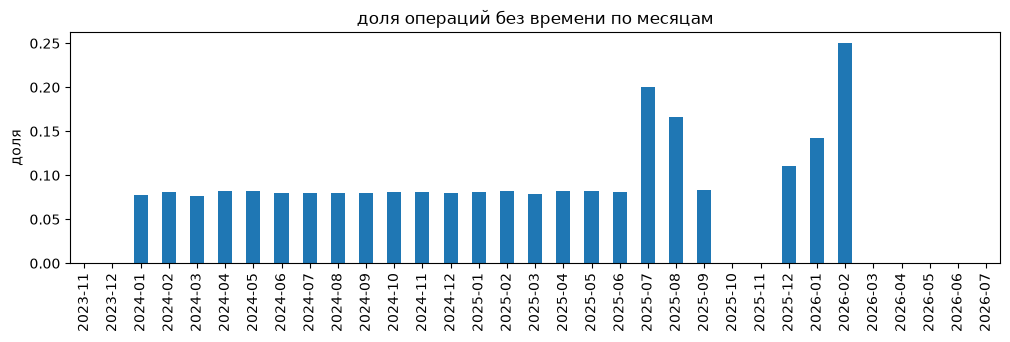

in period 2024-01 - 2025-06: min 0.077, max 0.083


In [23]:
# раздвоение форматов по месяцам
month = txn['txn_datetime'].str[:7]
only_date = other.groupby(month).mean()

only_date.plot.bar(figsize=(12, 3), title="доля операций без времени по месяцам")
plt.xlabel("")
plt.ylabel("доля")
plt.show()

print(f"in period 2024-01 - 2025-06: min {only_date['2024-01':'2025-06'].min():.3f}, max {only_date['2024-01':'2025-06'].max():.3f}")

график выше демонстрирует, что доли транзакций без времени в часах (% от всех за период, где период - месяц) внутри заявленного периода стабильны: от 0.077 до 0.083. На краях (вне периода) доли скачут из-за малого кол-ва транзакций в этих месяцах

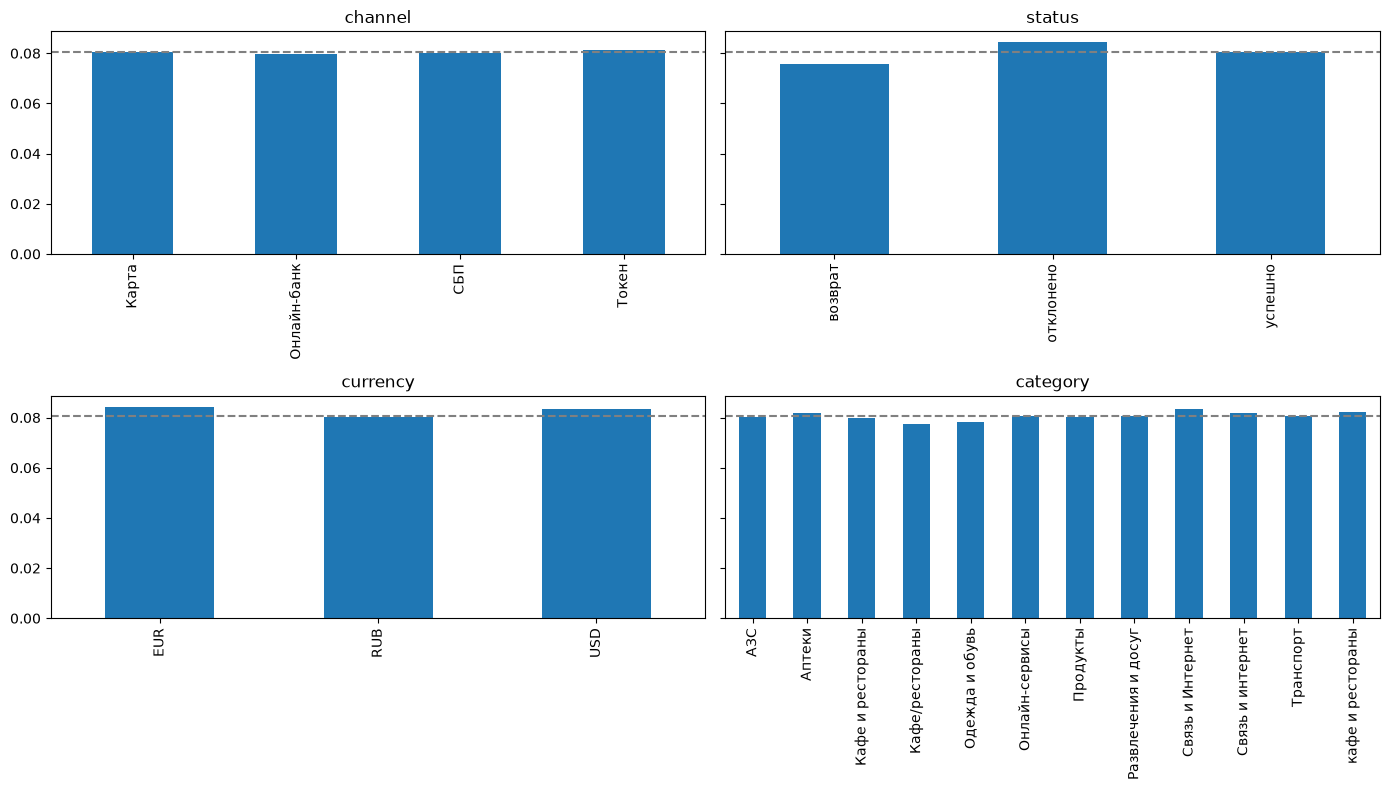

In [24]:
# разрезы с форматом без часов на остальных категориальных колонках
# пунктир - доля по всем операциям
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for ax, col in zip(axes.flatten(), ["channel", "status", "currency", "category"]):
    other.groupby(txn[col], observed=True).mean().plot.bar(ax=ax, title=col)
    ax.axhline(other.mean(), color="gray", linestyle="--")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

связи ни с одним другим признаком не выявлено, выглядит как случайная потеря времени(часов) в датах, т.к. везде колеблется около 8%. Время у этих операций (49623 из 616795, 8.05%) утрачено в источнике и восстановлено быть не может. При приведении к формату большинства необходимо будет дополнительно отметить эти строки флагом datetime_valid_hours = false чтобы искусственно приписанные часы можно было **быстро** отличить от истинных.

```txn_datetime``` - необходимо привести к единому формату, ко всем датам без часов добавить 00:00:00 и добавить столбец datetime_valid_hours=false для них (для остальных - true)

In [25]:
txn["datetime_valid_hours"] = txn["txn_datetime"].str.len() > 10
txn.loc[~txn["datetime_valid_hours"], "txn_datetime"] = txn["txn_datetime"] + " 00:00:00"
txn["txn_datetime"] = pd.to_datetime(txn["txn_datetime"], format="%Y-%m-%d %H:%M:%S", errors="raise")

print(f"without hours: {(~txn['datetime_valid_hours']).sum()} of total {txn.shape[0]}")
print(txn[["txn_datetime", "datetime_valid_hours"]].dtypes)

without hours: 49623 of total 616795
txn_datetime            datetime64[us]
datetime_valid_hours              bool
dtype: object


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```txn_datetime``` | нет времени, только дата | строки формата ```yyyy-mm-dd``` | 49623 | ```yyyy-mm-dd``` | заполнено | ```yyyy-mm-dd 00:00:00```, ```datetime_valid_hours = False``` | время утрачено случайно (~8% во всех разрезах, см. выше), восстановить нельзя; для помесячных подсчетов нужна только дата |

clients with USD/EUR txn: 1884 of total 5993
count    1884.000000
mean        0.013379
std         0.020473
min         0.001684
25%         0.006623
50%         0.009804
75%         0.014815
max         0.500000
Name: currency, dtype: float64


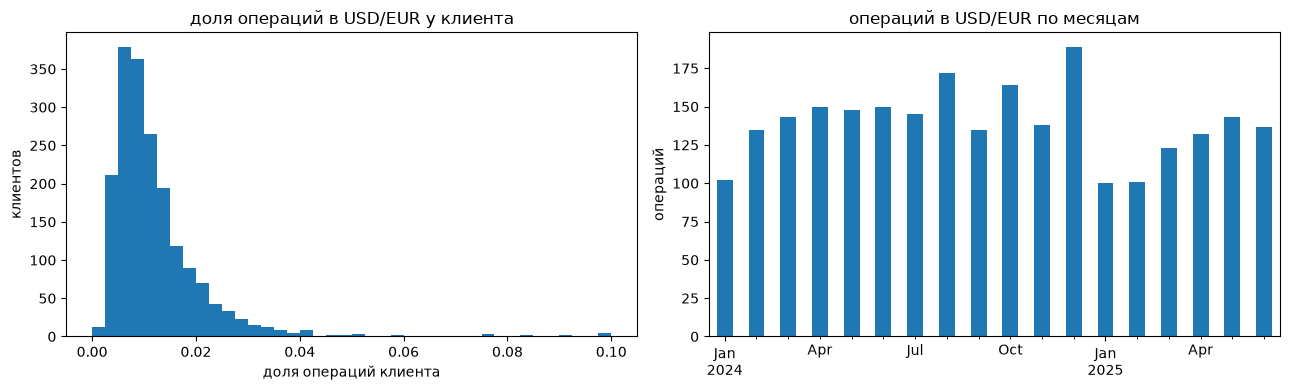

clients with share > 0.1 (not shown): 9


In [26]:
foreign = txn["currency"] != "RUB"
print(f"clients with USD/EUR txn: {txn.loc[foreign, 'client_id'].nunique()} of total {txn['client_id'].nunique()}")

share = foreign.groupby(txn["client_id"]).mean()
print(share[share > 0].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# доля операций в USD/EUR у клиента (только у тех, у кого они есть)
share[share > 0].plot.hist(bins=40, range=(0, 0.1), ax=axes[0])
axes[0].set_title("доля операций в USD/EUR у клиента")
axes[0].set_xlabel("доля операций клиента")
axes[0].set_ylabel("клиентов")

# число операций в USD/EUR по месяцам, только заявленный период
monthly = foreign.groupby(txn["txn_datetime"].dt.to_period("M")).sum()["2024-01":"2025-06"]
monthly.plot.bar(ax=axes[1])
axes[1].set_title("операций в USD/EUR по месяцам")
axes[1].set_xlabel("")
axes[1].set_ylabel("операций")

plt.tight_layout()
plt.show()

print(f"clients with share > 0.1 (not shown): {(share > 0.1).sum()}")

 операции в USD/EUR есть у 1884 клиентов из 5993, у половины из них это меньше 1% операций (медиана 0.98%), по месяцам распределены ровно. Только у 9 клиентов из 5993 (0.150%) доля больше 10% (max 50%)

| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```amount``` | сумма в исходной валюте, а не в рублях | ```txn['currency'] != 'RUB'``` | 2508 | медиана 11.40 USD, 10.775 EUR | оставлено как есть | без изменений | курса в данных нет, перевести в RUB нельзя; валютные операции распределены тонко (медиана 0.98% операций клиента), на число операций не влияют, суммы считаем только по RUB |

In [ ]:
# monthly_income < 1000 - в тысячах? сравниваем траты в месяц с доходом
# траты: рублевые операции в заявленном периоде в среднем за месяц (18 месяцев)
ok = (txn["status"] != "отклонено") & (txn["currency"] == "RUB") & (txn["txn_datetime"] >= "2024-01-01") & (txn["txn_datetime"] < "2025-07-01")
spend = txn[ok].groupby("client_id")["amount"].sum() / 18

inc = clients.drop_duplicates("client_id").set_index("client_id")["monthly_income"]
small = inc[(inc > 0) & (inc < 1000)].index
normal = inc[inc >= 10000].index

ratio = spend / inc
print(f"spend / income, income >= 10000: median {ratio[normal].median():.2f} ({len(normal)} clients)")
print(f"spend / income, 0 < income < 1000: median {ratio[small].median():.2f} ({len(small)} clients)")
print(f"spend / (income * 1000), 0 < income < 1000: median {(ratio[small] / 1000).median():.2f}")

spend / income, income >= 10000: median 0.10 (4835 clients)
spend / income, 0 < income < 1000: median 95.19 (171 clients)
spend / (income * 1000), 0 < income < 1000: median 0.10


у клиентов с нормальным доходом (>= 10000, 4835 клиентов) траты в месяц составляют 0.10 дохода (медиана). У 171 клиента с доходом от 0 до 1000 траты в 95.19 раз больше дохода, а после умножения дохода на 1000 - те же 0.10, что и у остальных. Значит доход у них указан в тысячах рублей

версия "в сотнях USD/EUR" не подходит: тогда доход в рублях был бы больше в ~9000 раз (×100 и по курсу ~90), и отношение упало бы до ~0.01


In [28]:
# доход от 0 до 1000 указан в тысячах - переводим в рубли
in_thousands = (clients["monthly_income"] > 0) & (clients["monthly_income"] < 1000)
clients.loc[in_thousands, "monthly_income"] = clients["monthly_income"] * 1000

print(f"multiplied by 1000: {in_thousands.sum()} of total {clients.shape[0]}")
print(f"min after: {clients.loc[in_thousands, 'monthly_income'].min():.0f}, max after: {clients.loc[in_thousands, 'monthly_income'].max():.0f}")

multiplied by 1000: 173 of total 5667
min after: 26900, max after: 658700


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```monthly_income``` | доход указан в тысячах рублей | ```0 < monthly_income < 1000``` | 173 | 62.4 | исправлено (×1000) | 62400 | в [1000; 10000) нет ни одного значения (2.3); траты этих клиентов в месяц сопоставимы с доходом только после умножения на 1000 |

In [29]:
# monthly_income < 0
neg = clients["monthly_income"] < 0
print(clients.loc[neg, "monthly_income"].value_counts())
print()

# траты в месяц: обычные ли это клиенты
neg_ids = inc[inc < 0].index
print(f"spend per month, income < 0: median {spend[spend.index.isin(neg_ids)].median():.0f}")
print(f"spend per month, income >= 10000: median {spend[spend.index.isin(normal)].median():.0f}")

monthly_income
-999.0    53
Name: count, dtype: int64

spend per month, income < 0: median 9907
spend per month, income >= 10000: median 7929


все клиенты с отрицательным доходом имеют траты чуть выше обычных клиентов, а также сам доход у них одинаковый: -999.0. Это свидетельствует о том что -999 это не отрицательный доход, а все такие доходы следует трактовать как NaN

In [30]:
clients.loc[neg, 'monthly_income'] = np.nan
print(f"set to NaN: {neg.sum()}")

set to NaN: 53


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```monthly_income``` | отрицательный доход | ```monthly_income == -999``` | 53 | -999 | заменено на NaN | NaN | все отрицательные значения ровно -999.0; клиенты обычные (траты как у остальных), доход неизвестен - NaN; |

### 3.2. Категориальные признаки

нормализуем написания ```city``` и ```category``` (выводы по аудиту, п. 1) и сверяем ```category``` с ```mcc_code``` (п. 8). Остальные категориальные колонки чистые (см. 1)

In [31]:
city = clients["city"].str.lower().str.replace("г.", "").str.strip()
city = city.replace({"спб": "санкт-петербург", "санкт петербург": "санкт-петербург", "н. новгород": "нижний новгород"})
city = city.str.title()

print(f"changed: {(clients['city'] != city).sum()} of total {clients.shape[0]}")
clients["city"] = city.astype("category")
print(clients["city"].value_counts())

changed: 1619 of total 5667
city
Москва             1634
Санкт-Петербург     969
Казань              959
Екатеринбург        717
Нижний Новгород     694
Новосибирск         694
Name: count, dtype: int64


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```city``` | разные написания одинаковых городов | все строки | 1619 | " москва", "г. Москва", "СПб" | нормализация | "Москва", "Санкт-Петербург" | 17 написаний -> 6 городов, смысл не меняется |

In [32]:
cat = txn["category"].astype(str).replace({
    "Связь и Интернет": "Связь и интернет",
    "Кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны",
})
print(f"changed: {(txn['category'] != cat).sum()} of total {txn.shape[0]}")
txn["category"] = cat.astype("category")
print(txn["category"].value_counts())

changed: 51117 of total 616795
category
Продукты               161434
Кафе и рестораны        80051
Транспорт               64520
Одежда и обувь          64068
АЗС                     56860
Развлечения и досуг     53202
Связь и интернет        48412
Аптеки                  45117
Онлайн-сервисы          43131
Name: count, dtype: int64


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```category``` | разные написания одинаковых категорий | все строки | 51117 | "Связь и Интернет", "Кафе/рестораны" | нормализация | "Связь и интернет", "Кафе и рестораны" | 12 написаний -> 9 категорий; смысл не меняется |

в 1599 строках из 616795 (0.259%) ```category``` не совпадает с ```mcc_code``` (2.3). Верим MCC: это технический код торговой точки. У каждого MCC одна основная категория, совпадающая с ним по смыслу, остальные строки раскиданы по всем категориям понемногу - похоже на ошибку разметки. Строки не удаляем, это настоящие операции, исправляем категорию на основную по MCC

In [33]:
# category по mcc_code: у каждого MCC берем его основную категорию
main_cat = pd.crosstab(txn["mcc_code"], txn["category"]).idxmax(axis=1)
print(main_cat)

fixed = txn["mcc_code"].map(main_cat)
print(f"changed: {(txn['category'].astype(str) != fixed).sum()} of total {txn.shape[0]}")
txn["category"] = fixed.astype("category")

mcc_code
4111              Транспорт
4814       Связь и интернет
5411               Продукты
5541                    АЗС
5651         Одежда и обувь
5812       Кафе и рестораны
5815         Онлайн-сервисы
5912                 Аптеки
7832    Развлечения и досуг
dtype: category
Categories (9, str): ['АЗС', 'Аптеки', 'Кафе и рестораны', 'Одежда и обувь', ..., 'Продукты', 'Развлечения и досуг', 'Связь и интернет', 'Транспорт']
changed: 1599 of total 616795


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```category``` | категория не соответствует ```mcc_code``` | строки, где category не основная для своего MCC | 1599 | mcc 5411, "АЗС" | исправлено по ```mcc_code``` | "Продукты" | MCC - технический код точки, категория - его расшифровка; у каждого MCC одна основная категория, расхождения раскиданы случайно (2.3) |

### 3.2. Дубли

полные копии удаляем, конфликты (одинаковый ключ, разные значения) разбираем отдельно (см. 2.2 и выводы по аудиту, п. 4). Считаем заново, т.к. после нормализации ```city``` часть конфликтов в ```clients``` могла стать полными копиями

In [34]:
# дубли после 3.1 - 3.2
dup_key = clients["client_id"].duplicated(keep=False)
full = clients.duplicated(keep=False)
print(f"clients: rows with duplicated key {dup_key.sum()} | full copy rows {(dup_key & full).sum()} | conflict rows {(dup_key & ~full).sum()}")

dup_key = txn["txn_id"].duplicated(keep=False)
full = txn.duplicated(keep=False)
print(f"txn: rows with duplicated key {dup_key.sum()} | full copy rows {(dup_key & full).sum()} | conflict rows {(dup_key & ~full).sum()}")

clients: rows with duplicated key 110 | full copy rows 80 | conflict rows 30
txn: rows with duplicated key 3000 | full copy rows 2602 | conflict rows 398


In [35]:
# полные копии - удаляем, оставляем по одной строке
n_before = clients.shape[0]
clients = clients.drop_duplicates().reset_index(drop=True)
print(f"clients: removed {n_before - clients.shape[0]} full copies | rows {clients.shape[0]}")

n_before = txn.shape[0]
txn = txn.drop_duplicates().reset_index(drop=True)
print(f"txn: removed {n_before - txn.shape[0]} full copies | rows {txn.shape[0]}")

clients: removed 40 full copies | rows 5627
txn: removed 1301 full copies | rows 615494


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| все поля ```clients``` | полная копия строки | ```clients.duplicated()``` | 40 | две одинаковые строки клиента | удалено | одна строка | копия не несет информации, клиент считался бы дважды |
| все поля ```txn``` | полная копия строки | ```txn.duplicated()``` | 1301 | две одинаковые строки операции | удалено | одна строка | копия не несет информации, операция считалась бы дважды |

In [36]:
# txn: конфликты по txn_datetime - чем отличаются копии
conf = txn[txn["txn_id"].duplicated(keep=False)]
print(f"conflict rows: {conf.shape[0]} | keys: {conf['txn_id'].nunique()}")

# у скольких пар ровно у одной копии нет времени
no_time = (~conf["datetime_valid_hours"]).groupby(conf["txn_id"]).sum()
print(no_time.value_counts().sort_index())

# одна ли дата у копий
same_day = conf["txn_datetime"].dt.date.groupby(conf["txn_id"]).nunique() == 1
print(f"pairs with same date: {same_day.sum()}")

# разница во времени между копиями
gap = conf.groupby("txn_id")["txn_datetime"].max() - conf.groupby("txn_id")["txn_datetime"].min()
print(gap.describe())

conflict rows: 398 | keys: 199
datetime_valid_hours
1    199
Name: count, dtype: int64
pairs with same date: 199
count                       199
mean     0 days 14:34:28.934673
std      0 days 04:14:51.488359
min             0 days 02:02:08
25%      0 days 11:42:27.500000
50%             0 days 14:25:43
75%             0 days 17:22:59
max             0 days 23:59:34
Name: txn_datetime, dtype: object


у всех 199 пар у одной копии нет времени, а у другой есть, и дата у копий одна и та же (199 из 199). Разница от 2 до 24 часов - это просто время суток у копии со временем, т.к. у второй стоит 00:00:00. Т.е. это одна и та же операция, у одной копии которой потеряно время (как у остальных 8%, см. 3.1). Оставляем копию со временем

In [37]:
# txn: из каждой пары удаляем копию без времени
drop = txn["txn_id"].duplicated(keep=False) & ~txn["datetime_valid_hours"]
print(f"removed: {drop.sum()}")
txn = txn[~drop].reset_index(drop=True)
print(f"rows {txn.shape[0]} | unique txn_id {txn['txn_id'].nunique()}")

removed: 199
rows 615295 | unique txn_id 615295


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```txn_datetime``` | конфликт копий: у одной нет времени | ```txn_id``` с двумя версиями | 199 | ```yyyy-mm-dd 00:00:00``` и ```yyyy-mm-dd hh:mm:ss``` | удалено (копия без времени) | одна строка со временем | дата у копий совпадает в 199 из 199, у одной копии время потеряно - это одна операция |

In [38]:
# clients: конфликты после нормализации city - какие поля расходятся
conf = clients[clients["client_id"].duplicated(keep=False)]
diff = (conf.groupby("client_id").nunique(dropna=False) > 1).sum()
print(f"conflict keys: {conf['client_id'].nunique()}")
print(diff[diff > 0])
print()
print(conf.sort_values("client_id")[["client_id", "segment", "city", "income_source", "card_type", "loyalty_tier"]])

conflict keys: 15
city       11
segment    13
dtype: int64

     client_id      segment             city            income_source    card_type loyalty_tier
2522   C000004     Массовый           Казань  Зарплата в другом банке    Кредитная      Базовый
2970   C000004   Зарплатный           Казань  Зарплата в другом банке    Кредитная      Базовый
496    C000607     Массовый     Екатеринбург                Не указан    Дебетовая      Базовый
1074   C000607   Зарплатный     Екатеринбург                Не указан    Дебетовая      Базовый
651    C001319     Массовый      Новосибирск                Не указан    Дебетовая      Базовый
5295   C001319     Массовый           Москва                Не указан    Дебетовая      Базовый
1685   C001355   Зарплатный           Москва   Зарплата в нашем банке    Дебетовая      Серебро
4301   C001355  Премиальный      Новосибирск   Зарплата в нашем банке    Дебетовая      Серебро
1497   C002490      Private  Нижний Новгород                Не указан  Преми

после нормализации ```city``` ни один конфликт не стал полной копией: по-прежнему 15 ключей, ```city``` расходится у 11, ```segment``` у 13, и это разные города (Москва и Новосибирск у C001319), а не написания. Остальные поля у копий совпадают, поэтому какая версия верная - по данным не понять. ```income_source``` помогает только в паре случаев (Зарплатный при "Зарплата в другом банке" у C000004), а большинство пар - Массовый против Private при дебетовой карте

клиентов не удаляем (у них есть операции), оставляем одну строку, а расходящееся поле ставим NaN - это 15 клиентов из 5612 (0.267%)

In [39]:
# clients: расходящиеся segment / city -> NaN, затем копии становятся одинаковыми
dup = clients["client_id"].duplicated(keep=False)
seg_n = clients[dup].groupby("client_id")["segment"].nunique()
city_n = clients[dup].groupby("client_id")["city"].nunique()
print(f"segment conflicts: {(seg_n > 1).sum()} | city conflicts: {(city_n > 1).sum()}")

clients.loc[clients["client_id"].isin(seg_n[seg_n > 1].index), "segment"] = np.nan
clients.loc[clients["client_id"].isin(city_n[city_n > 1].index), "city"] = np.nan
clients = clients.drop_duplicates().reset_index(drop=True)
print(f"rows {clients.shape[0]} | unique client_id {clients['client_id'].nunique()}")

segment conflicts: 13 | city conflicts: 11
rows 5612 | unique client_id 5612


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```segment```, ```city``` | конфликт копий: разные segment / city | 15 ```client_id``` с двумя версиями | 30 | "Массовый" и "Private" (C002609), "Москва" и "Новосибирск" (C001319) | заменено на NaN, оставлена одна строка | NaN | верную версию определить нельзя, остальные поля совпадают; клиентов не удаляем, у них есть операции |

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [40]:
# пропуски после 3.1 - 3.2
na = clients.isna().sum()
print(pd.DataFrame({"n": na, "rate %": (na / clients.shape[0] * 100).round(3)})[na > 0])
print(f"\ntxn without time: {(~txn['datetime_valid_hours']).sum()} of total {txn.shape[0]}")
print(f"txn NaN: {txn.isna().sum().sum()}")

                       n  rate %
city                  11   0.196
segment               13   0.232
monthly_income       606  10.798
app_last_login      2190  39.024
satisfaction_score  3285  58.535

txn without time: 49416 of total 615295
txn NaN: 0


In [41]:
# механизм пропусков: доля NaN в разрезах
inc_na = clients["monthly_income"].isna()
print(inc_na.groupby(clients["income_source"], observed=True).mean().round(3), "\n")
print(inc_na.groupby(clients["segment"], observed=True).mean().round(3), "\n")

sat_na = clients["satisfaction_score"].isna()
print(sat_na.groupby(clients["segment"], observed=True).mean().round(3), "\n")
print(sat_na.groupby(clients["has_mobile_app"]).mean().round(3), "\n")

# число операций у клиентов с оценкой и без
n_txn = clients["client_id"].map(txn["client_id"].value_counts())
print(f"median txn, income NaN: {n_txn[inc_na].median()} | income filled: {n_txn[~inc_na].median()}")
print(f"median txn, satisfaction NaN: {n_txn[sat_na].median()} | satisfaction filled: {n_txn[~sat_na].median()}")

income_source
Зарплата в другом банке    0.045
Зарплата в нашем банке     0.050
Не указан                  0.259
Name: monthly_income, dtype: float64 

segment
Private        0.114
Зарплатный     0.064
Массовый       0.134
Премиальный    0.098
Name: monthly_income, dtype: float64 

segment
Private        0.364
Зарплатный     0.591
Массовый       0.636
Премиальный    0.472
Name: satisfaction_score, dtype: float64 

has_mobile_app
False    0.587
True     0.584
Name: satisfaction_score, dtype: float64 

median txn, income NaN: 89.0 | income filled: 88.0
median txn, satisfaction NaN: 86.0 | satisfaction filled: 91.0


```monthly_income``` - 606 NaN из 5612 (10.798%). Механизм MAR: пропуск зависит от ```income_source``` - у "Не указан" дохода нет у 25.9% клиентов, у остальных около 5% (4.5% и 5.0%), т.е. кто не назвал источник дохода, чаще не назвал и сам доход. С активностью не связан: медиана операций 89 против 88. Не заполняем: медиана или мода придумали бы доход четверти клиентов с "Не указан", а для метрики активности доход не нужен. Если доход войдет в правило группы, клиенты с NaN под условие по доходу просто не попадут

```satisfaction_score``` - 3285 NaN из 5612 (58.535%). Механизм MAR: зависит от сегмента - опрос не проходили 36.4% Private, 47.2% Премиальных, 59.1% Зарплатных и 63.6% Массовых, т.е. опрос чаще доходит до дорогих сегментов. От приложения не зависит (58.7% и 58.4%), клиенты без оценки делают чуть меньше операций (медиана 86 против 91). Не заполняем и как признак групп не используем: больше половины пропусков, а заполненные смещены к Private и Премиальным

```app_last_login``` - 2190 NaN из 5612 (39.024%). Это не пропуск, а отсутствие приложения: NaN ровно у клиентов с ```has_mobile_app``` = False (см. 2.3). Оставляем NaN, это корректное значение

```segment``` (13 из 5612, 0.232%) и ```city``` (11 из 5612, 0.196%) - NaN поставлены в 3.2 из-за конфликтов дублей, верная версия неизвестна. Оставляем: эти 15 клиентов из 5612 (0.267%) не попадут в правила групп по сегменту или городу

```txn_datetime``` - время отсутствует у 49416 операций из 615295 (8.031%), MCAR (см. 3.1), заполнено 00:00:00 с флагом ```datetime_valid_hours```

в ```txn``` пропусков нет (0): категорию брали по MCC без пропусков, дату парсили с errors="raise"

```income_source``` = "Не указан" (1598 из 5667 до удаления дублей, см. 1) - по смыслу тоже пропуск, но оставляем как отдельное значение: это ответ клиента, и от него зависит пропуск дохода (см. выше)

| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```monthly_income``` | пропуск дохода (MAR, чаще при ```income_source``` "Не указан") | ```monthly_income``` is NaN | 606 | NaN | оставлено | NaN | для метрики активности не нужен; заполнение придумало бы доход четверти клиентов с "Не указан" |
| ```satisfaction_score``` | пропуск оценки (MAR, зависит от сегмента) | ```satisfaction_score``` is NaN | 3285 | NaN | оставлено, в группах не используется | NaN | 58.535% пропусков, заполненные смещены к Private и Премиальным |
| ```app_last_login``` | NaN у клиентов без приложения | ```has_mobile_app``` = False | 2190 | NaN | оставлено | NaN | не пропуск, а отсутствие приложения |
| ```segment```, ```city``` | NaN после конфликтов дублей | 15 ```client_id``` | 15 | NaN | оставлено | NaN | верная версия неизвестна (см. 3.2) |

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [42]:
# обнаружение: amount, рублевые операции, по модулю (возвраты отрицательные)
a = txn.loc[txn["currency"] == "RUB", "amount"].abs()
print(a.describe(percentiles=[0.25, 0.5, 0.75, 0.99, 0.999]).round(2))

q1, q3 = a.quantile(0.25), a.quantile(0.75)
a_upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: {a_upper:.2f} | above: {(a > a_upper).sum()} of total {a.shape[0]} ({(a > a_upper).mean()*100:.3f}%)")
print(f"above 3 IQR: {(a > q3 + 3 * (q3 - q1)).sum()}")

# для сравнения - правило 3 сигм
mean, std = a.mean(), a.std()
print(f"3 sigma: lower {mean - 3 * std:.2f}, upper {mean + 3 * std:.2f} | above: {(a > mean + 3 * std).sum()} | mean {mean:.2f} vs median {a.median():.2f}")

count    612791.00
mean       1939.36
std        2703.98
min           5.34
25%         496.72
50%        1104.14
75%        2310.35
99%       12963.67
99.9%     26838.07
max       97323.86
Name: amount, dtype: float64
IQR upper fence: 5030.80 | above: 49866 of total 612791 (8.138%)
above 3 IQR: 21521
3 sigma: lower -6172.56, upper 10051.29 | above: 11758 | mean 1939.36 vs median 1104.14


```amount``` (рублевые, по модулю): граница IQR (Q3 + 1.5·IQR) 5030.80, выше нее 49866 операций из 612791 (8.138%), выше 3·IQR 21521; по 3 сигмам (выше 10051.29) - 11758. Берем IQR, а не 3 сигмы: среднее 1939.36 против медианы 1104.14 - распределение скошено вправо и среднее тянет хвост, нижняя граница 3 сигм отрицательная (-6172.56) и смысла не имеет, а верхняя зависит от тех самых больших значений, которые мы ищем. Квартили от хвоста не зависят

In [43]:
# обнаружение: monthly_income (после исправлений в 3.1)
income = clients["monthly_income"].dropna()
print(income.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(0))

q1, q3 = income.quantile(0.25), income.quantile(0.75)
i_upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: {i_upper:.0f} | above: {(income > i_upper).sum()} of total {income.shape[0]} ({(income > i_upper).mean()*100:.3f}%)")
print(f"above 3 IQR: {(income > q3 + 3 * (q3 - q1)).sum()}")
print(income.sort_values(ascending=False).head(10).values)

# для сравнения - правило 3 сигм
mean, std = income.mean(), income.std()
print(f"3 sigma: lower {mean - 3 * std:.0f}, upper {mean + 3 * std:.0f} | above: {(income > mean + 3 * std).sum()} | mean {mean:.0f} vs median {income.median():.0f}")

# кто эти клиенты с доходом выше границы IQR
print(clients.loc[clients["monthly_income"] > i_upper, "segment"].value_counts())

count       5006.0
mean       99222.0
std        82504.0
min        13900.0
25%        54500.0
50%        74900.0
75%       111300.0
99%       488410.0
max      1018800.0
Name: monthly_income, dtype: float64


IQR upper fence: 196500 | above: 401 of total 5006 (8.010%)
above 3 IQR: 192
[1018800.  906500.  896900.  748100.  727300.  718100.  697900.  696000.
  683100.  669100.]
3 sigma: lower -148288, upper 346733 | above: 117 | mean 99222 vs median 74900
segment
Private        202
Премиальный    183
Зарплатный      11
Массовый         5
Name: count, dtype: int64


```monthly_income```: граница IQR 196500, выше нее 401 клиент из 5006 (8.010%), выше 3·IQR 192; по 3 сигмам (выше 346733) - 117. IQR по той же причине: среднее 99222 против медианы 74900, нижняя граница 3 сигм отрицательная (-148288). Максимум 1018800. Из 401 клиента 385 (96.0%) - Private и Премиальные, 16 (4.0%) - Массовый и Зарплатный

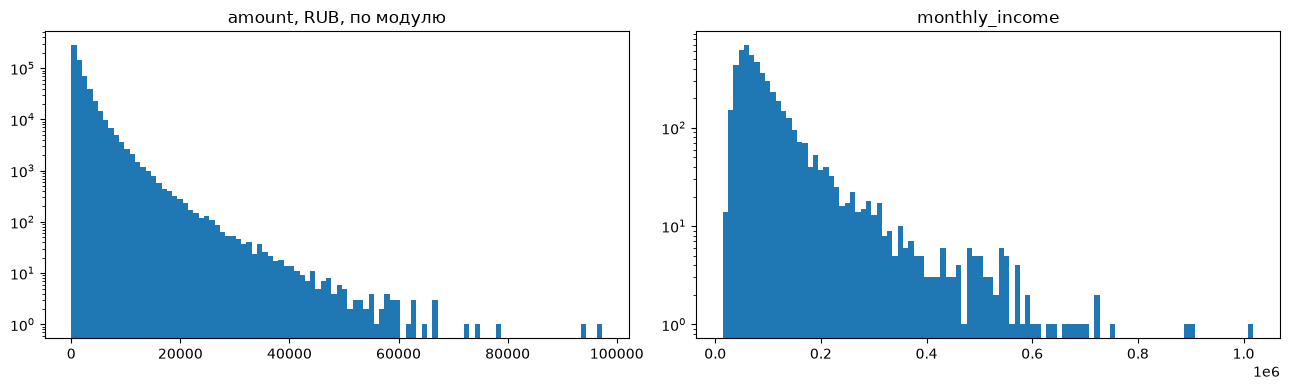

In [44]:
# распределения: ось y в логарифме, чтобы были видны редкие большие значения
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(a, bins=100, log=True)
axes[0].set_title("amount, RUB, по модулю")
axes[1].hist(income, bins=100, log=True)
axes[1].set_title("monthly_income")
plt.tight_layout()
plt.show()

оба распределения скошены вправо, хвосты плавно сходят на нет: у ```amount``` до ~60 тыс., дальше единичные операции до 97323.86, у дохода до ~750 тыс., дальше 3 значения до 1018800. Невозможных значений (нулевых, отрицательных, оторванных на порядки) нет

In [45]:
# крупные операции (выше границы IQR): чем отличаются от остальных
rub = txn[txn["currency"] == "RUB"]
large = rub["amount"].abs() > a_upper
print(pd.crosstab(rub["category"], large, normalize="columns").round(3), "\n")
print(pd.crosstab(rub["status"], large, normalize="columns").round(3), "\n")
print(pd.crosstab(rub["channel"], large, normalize="columns").round(3))

amount               False  True 
category                         
АЗС                  0.091  0.109
Аптеки               0.079  0.007
Кафе и рестораны     0.132  0.099
Одежда и обувь       0.067  0.526
Онлайн-сервисы       0.076  0.001
Продукты             0.280  0.048
Развлечения и досуг  0.076  0.207
Связь и интернет     0.085  0.002
Транспорт            0.114  0.000 

amount     False  True 
status                 
возврат    0.012  0.011
отклонено  0.018  0.048
успешно    0.970  0.941 

amount       False  True 
channel                  
Карта        0.513  0.516
Онлайн-банк  0.152  0.150
СБП          0.170  0.168
Токен        0.166  0.166


крупные операции - это в первую очередь одежда и развлечения: "Одежда и обувь" 52.6% крупных против 6.7% остальных, "Развлечения и досуг" 20.7% против 7.6%; в транспорте, связи, онлайн-сервисах и аптеках крупных почти нет (0.0% - 0.7%). Т.е. размер суммы определяется тем, что покупают, - это ожидаемо и подтверждает, что хвост естественный

среди крупных чаще отклоненные: 4.8% против 1.8% - крупную покупку чаще не пропускает лимит или баланс. Возвраты (1.1% и 1.2%) и каналы (доли совпадают до 0.003) от размера суммы не зависят

решение: выбросы не удаляем и не обрезаем ни в ```amount```, ни в ```monthly_income```. Это не ошибки, а естественный хвост: крупные покупки плавно сходят на нет, а высокий доход почти весь у Private и Премиальных, для которых он ожидаем. При скошенном распределении граница IQR показывает, где начинается хвост, а не где ошибка - она отсекает ~8% обычных значений. Чтобы крупные суммы не перекашивали выводы, дальше для сумм используем медианы, а не средние. Оставляем и помечаем флагами ```large_amount``` и ```high_income```, чтобы в главе 6 проверить, не держатся ли выводы на крупных суммах

In [46]:
# флаги выбросов: значения остаются, но их можно быстро отделить
txn["large_amount"] = (txn["currency"] == "RUB") & (txn["amount"].abs() > a_upper)
clients["high_income"] = clients["monthly_income"] > i_upper
print(f"large_amount: {txn['large_amount'].sum()} of {txn.shape[0]}")
print(f"high_income: {clients['high_income'].sum()} of {clients.shape[0]}")

large_amount: 49866 of 615295
high_income: 401 of 5612


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```amount``` | выше границы IQR (5030.80) | рублевые операции, \|amount\| > 5030.80 | 49866 | до 97323.86 | оставлено, флаг | ```large_amount``` = True | естественный хвост трат, невозможных значений нет; для сумм используем медианы |
| ```monthly_income``` | выше границы IQR (196500) | ```monthly_income``` > 196500 | 401 | до 1018800 | оставлено, флаг | ```high_income``` = True | 96.0% - Private и Премиальные, высокий доход для них ожидаем |

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

```txn``` после главы 3 - очищенная таблица всех операций, ее сохраняем как есть. Для расчета метрики (глава 6) отбираем из нее ```txn_f```: только заявленный период и только клиенты из ```clients```. Статусы не фильтруем: отклоненные операции - это попытка клиента воспользоваться картой, а возврат отменяет прошлую покупку, и если его убрать, покупка останется в суммах, как будто ее не отменяли. Связать возврат с его покупкой нельзя (ссылки на исходную операцию в данных нет), поэтому как учитывать возвраты в числе операций и в суммах - решаем в главе 6 вместе с метрикой

```marketing_opt_in``` здесь не фильтруем: где и почему упало число операций, считаем по всем клиентам, а согласие применяем при отборе в группы (глава 7) - так в 7.1 видно, сколько клиентов не взяли из-за отсутствия согласия

In [47]:
# воронка, шаг 1: заявленный период 2024-01 - 2025-06
print(f"start: {txn.shape[0]}")
in_period = (txn["txn_datetime"] >= "2024-01-01") & (txn["txn_datetime"] < "2025-07-01")
txn_f = txn[in_period]
print(f"1. in period: {txn_f.shape[0]} (removed {(~in_period).sum()})")

start: 615295
1. in period: 615211 (removed 84)


из 615295 операций вне периода 84 (0.014%) - те же 84, что в 2.1, дубли их не задели

In [48]:
# операции клиентов не из clients - обрываются ли они до конца периода (см. 2.4)
last = txn_f.groupby("client_id")["txn_datetime"].max()
not_in = ~last.index.isin(clients["client_id"])
print(f"clients not in clients: {not_in.sum()} | in clients: {(~not_in).sum()}")
print(f"last txn before 2025-04: not in clients {(last[not_in] < '2025-04-01').mean():.3f} | in clients {(last[~not_in] < '2025-04-01').mean():.3f}")
print(last[not_in].dt.to_period("M").value_counts().sort_index())

clients not in clients: 388 | in clients: 5605
last txn before 2025-04: not in clients 1.000 | in clients 0.016
txn_datetime
2024-09     1
2024-10    66
2024-11    67
2024-12    66
2025-01    56
2025-02    69
2025-03    63
Freq: M, Name: count, dtype: int64


у всех 388 клиентов не из ```clients``` последняя операция раньше 2025-04 (1.000), у клиентов из справочника - только у 1.6%. Последние операции равномерно распределены с 2024-10 по 2025-03 (56-69 клиентов в месяц). Т.е. это ушедшие клиенты, которых уже нет в справочнике действующих на 30.06.2025 (см. 2.4). Их падение до нуля - это уход из банка, а не снижение использования карты, и в кампанию их не взять: нет признаков и согласия. Убираем

In [49]:
# воронка, шаг 2: только клиенты из clients
known = txn_f["client_id"].isin(clients["client_id"])
txn_f = txn_f[known]
print(f"2. client in clients: {txn_f.shape[0]} (removed {(~known).sum()})")

2. client in clients: 584771 (removed 30440)


убрано 30440 операций (4.948% от 615211) - меньше, чем 30509 в 2.4, т.к. часть их операций ушла с дублями и периодом

In [50]:
# клиенты после фильтров и согласие на коммуникацию (для главы 7)
print(f"clients with txn in txn_f: {txn_f['client_id'].nunique()} of {clients.shape[0]}")
print(f"clients without txn: {(~clients['client_id'].isin(txn_f['client_id'])).sum()}")
print(clients["marketing_opt_in"].value_counts())

clients with txn in txn_f: 5605 of 5612
clients without txn: 7
marketing_opt_in
True     4925
False     687
Name: count, dtype: int64


после фильтров операции есть у 5605 клиентов из 5612, у 7 (0.125%) операций нет ни в одном периоде - сравнивать у них нечего, в главе 6 они не попадут в расчет. Согласие на коммуникацию есть у 4925 клиентов, нет у 687 из 5612 (12.242%) - учитываем при отборе в группы в главе 7

воронка ```txn_f```:

| шаг | строк | убрано |
|---|---|---|
| ```txn``` после главы 3 | 615295 | - |
| 1. период 2024-01 - 2025-06 | 615211 | 84 |
| 2. клиент есть в ```clients``` | 584771 | 30440 |


| колонка | проблема | охват | кол-во строк | значение до | действие | значение после | почему |
|---|---|---|---|---|---|---|---|
| ```txn_datetime``` | операция вне заявленного периода | до 2024-01-01 и после 2025-06-30 | 84 | 2023-11 - 2026-07 | удалено из ```txn_f``` | - | не относится ни к базовому, ни к оцениваемому периоду |
| ```client_id``` | клиента нет в ```clients``` | 388 ```client_id``` | 30440 | - | удалено из ```txn_f``` | - | ушедшие клиенты: последняя операция у всех до 2025-04; нет признаков и согласия |

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [51]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [52]:
# все решения главы 3 - по строке на решение (md-таблицы под решениями)
rows = [
    # 3.1
    ["txn_datetime", "нет времени, только дата", "строки формата yyyy-mm-dd", 49623, "yyyy-mm-dd", "заполнено", "yyyy-mm-dd 00:00:00, datetime_valid_hours = False", "время утрачено случайно (~8% во всех разрезах, 3.1), восстановить нельзя; для помесячных подсчетов нужна только дата"],
    ["amount", "сумма в исходной валюте, а не в рублях", "currency != RUB", 2508, "медиана 11.40 USD, 10.775 EUR", "оставлено", "без изменений", "курса в данных нет, перевести в RUB нельзя; валютные операции распределены тонко (медиана 0.98% операций клиента), на число операций не влияют, суммы считаем только по RUB"],
    ["monthly_income", "доход указан в тысячах рублей", "0 < monthly_income < 1000", 173, "62.4", "исправлено (×1000)", "62400", "в [1000; 10000) нет ни одного значения (2.3); траты этих клиентов в месяц сопоставимы с доходом только после умножения на 1000"],
    ["monthly_income", "отрицательный доход", "monthly_income == -999", 53, "-999", "заменено на NaN", "NaN", "все отрицательные значения ровно -999.0; клиенты обычные (траты как у остальных), доход неизвестен"],
    # 3.2
    ["city", "разные написания одинаковых городов", "все строки", 1619, '" москва", "г. Москва", "СПб"', "нормализация", '"Москва", "Санкт-Петербург"', "17 написаний -> 6 городов, смысл не меняется"],
    ["category", "разные написания одинаковых категорий", "все строки", 51117, '"Связь и Интернет", "Кафе/рестораны"', "нормализация", '"Связь и интернет", "Кафе и рестораны"', "12 написаний -> 9 категорий, смысл не меняется"],
    ["category", "категория не соответствует mcc_code", "строки, где category не основная для своего MCC", 1599, 'mcc 5411, "АЗС"', "исправлено по mcc_code", '"Продукты"', "MCC - технический код точки, категория - его расшифровка; у каждого MCC одна основная категория, расхождения раскиданы случайно (2.3)"],
    # 3.2. дубли
    ["все поля clients", "полная копия строки", "clients.duplicated()", 40, "две одинаковые строки клиента", "удалено", "одна строка", "копия не несет информации, клиент считался бы дважды"],
    ["все поля txn", "полная копия строки", "txn.duplicated()", 1301, "две одинаковые строки операции", "удалено", "одна строка", "копия не несет информации, операция считалась бы дважды"],
    ["txn_datetime", "конфликт копий: у одной нет времени", "txn_id с двумя версиями", 199, "yyyy-mm-dd 00:00:00 и yyyy-mm-dd hh:mm:ss", "удалено (копия без времени)", "одна строка со временем", "дата у копий совпадает в 199 из 199, у одной копии время потеряно - это одна операция"],
    ["segment, city", "конфликт копий: разные segment / city", "15 client_id с двумя версиями", 30, '"Массовый" и "Private" (C002609), "Москва" и "Новосибирск" (C001319)', "заменено на NaN, оставлена одна строка", "NaN", "верную версию определить нельзя, остальные поля совпадают; клиентов не удаляем, у них есть операции"],
    # 3.3
    ["monthly_income", 'пропуск дохода (MAR, чаще при income_source "Не указан")', "monthly_income is NaN", 606, "NaN", "оставлено", "NaN", 'для метрики не нужен; заполнение придумало бы доход четверти клиентов с "Не указан"'],
    ["satisfaction_score", "пропуск оценки (MAR, зависит от сегмента)", "satisfaction_score is NaN", 3285, "NaN", "оставлено, в группах не используется", "NaN", "58.535% пропусков, заполненные смещены к Private и Премиальным"],
    ["app_last_login", "NaN у клиентов без приложения", "has_mobile_app = False", 2190, "NaN", "оставлено", "NaN", "не пропуск, а отсутствие приложения"],
    ["segment, city", "NaN после конфликтов дублей", "15 client_id", 15, "NaN", "оставлено", "NaN", "верная версия неизвестна (дубли)"],
    # 3.4
    ["amount", "выше границы IQR (5030.80)", "рублевые операции, |amount| > 5030.80", 49866, "до 97323.86", "оставлено, флаг", "large_amount = True", "естественный хвост трат, невозможных значений нет; для сумм используем медианы"],
    ["monthly_income", "выше границы IQR (196500)", "monthly_income > 196500", 401, "до 1018800", "оставлено, флаг", "high_income = True", "96.0% - Private и Премиальные, высокий доход для них ожидаем"],
    # 3.5
    ["txn_datetime", "операция вне заявленного периода", "до 2024-01-01 и после 2025-06-30", 84, "2023-11 - 2026-07", "удалено из txn_f", "-", "не относится ни к базовому, ни к оцениваемому периоду"],
    ["client_id", "клиента нет в clients", "388 client_id", 30440, "-", "удалено из txn_f", "-", "ушедшие клиенты: последняя операция у всех до 2025-04; нет признаков и согласия"],
]
cleaning_log = pd.DataFrame(rows, columns=cleaning_log.columns)
print(f"decisions: {cleaning_log.shape[0]}")
cleaning_log

decisions: 19


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,txn_datetime,"нет времени, только дата",строки формата yyyy-mm-dd,49623,yyyy-mm-dd,заполнено,"yyyy-mm-dd 00:00:00, datetime_valid_hours = False","время утрачено случайно (~8% во всех разрезах,..."
1,amount,"сумма в исходной валюте, а не в рублях",currency != RUB,2508,"медиана 11.40 USD, 10.775 EUR",оставлено,без изменений,"курса в данных нет, перевести в RUB нельзя; ва..."
2,monthly_income,доход указан в тысячах рублей,0 < monthly_income < 1000,173,62.4,исправлено (×1000),62400,в [1000; 10000) нет ни одного значения (2.3); ...
3,monthly_income,отрицательный доход,monthly_income == -999,53,-999,заменено на NaN,NaN,все отрицательные значения ровно -999.0; клиен...
4,city,разные написания одинаковых городов,все строки,1619,""" москва"", ""г. Москва"", ""СПб""",нормализация,"""Москва"", ""Санкт-Петербург""","17 написаний -> 6 городов, смысл не меняется"
5,category,разные написания одинаковых категорий,все строки,51117,"""Связь и Интернет"", ""Кафе/рестораны""",нормализация,"""Связь и интернет"", ""Кафе и рестораны""","12 написаний -> 9 категорий, смысл не меняется"
6,category,категория не соответствует mcc_code,"строки, где category не основная для своего MCC",1599,"mcc 5411, ""АЗС""",исправлено по mcc_code,"""Продукты""","MCC - технический код точки, категория - его р..."
7,все поля clients,полная копия строки,clients.duplicated(),40,две одинаковые строки клиента,удалено,одна строка,"копия не несет информации, клиент считался бы ..."
8,все поля txn,полная копия строки,txn.duplicated(),1301,две одинаковые строки операции,удалено,одна строка,"копия не несет информации, операция считалась ..."
9,txn_datetime,конфликт копий: у одной нет времени,txn_id с двумя версиями,199,yyyy-mm-dd 00:00:00 и yyyy-mm-dd hh:mm:ss,удалено (копия без времени),одна строка со временем,"дата у копий совпадает в 199 из 199, у одной к..."


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

дальше работаем с очищенными ```clients``` и ```txn_f``` (операции за период 2024-01 - 2025-06 клиентов из справочника, см. 3.5). Количественные признаки клиента считаем на 30.06.2025 (```snap``` из 2.3): возраст, сколько лет клиент в банке, сколько лет текущей карте. Плюс число операций клиента за весь период

In [53]:
# количественные признаки клиента на 30.06.2025
clients["age"] = ((snap - clients["birth_date"]).dt.days / 365.25).astype(int)
clients["tenure_years"] = ((snap - clients["registration_date"]).dt.days / 365.25).round(1)
clients["card_age_years"] = ((snap - clients["card_open_date"]).dt.days / 365.25).round(1)

features = {
    "amount, RUB, |amount|": txn_f.loc[txn_f["currency"] == "RUB", "amount"].abs(),
    "monthly_income": clients["monthly_income"],
    "satisfaction_score": clients["satisfaction_score"],
    "age": clients["age"],
    "tenure_years": clients["tenure_years"],
    "card_age_years": clients["card_age_years"],
    "txn per client (18 months)": txn_f["client_id"].value_counts(),
}

# меры центра и разброса рядом: среднее/медиана, std/IQR, плюс асимметрия
rows = []
for name, s in features.items():
    rows.append([name, s.count(), s.mean(), s.median(), s.std(), s.quantile(0.75) - s.quantile(0.25), s.skew()])
desc = pd.DataFrame(rows, columns=["feature", "n", "mean", "median", "std", "IQR", "skew"]).set_index("feature").round(2)
desc

,n,mean,median,std,IQR,skew
feature,,,,,,
"amount, RUB, |amount|",582382,1941.52,1104.7,2709.14,1816.06,5.04
monthly_income,5006,99222.35,74900.0,82503.59,56800.00,3.63
satisfaction_score,2327,3.29,3.0,1.38,3.00,-0.19
age,5612,53.05,51.0,13.94,19.00,0.54
tenure_years,5612,7.81,7.8,3.25,4.80,-0.05
card_age_years,5612,4.80,4.8,2.74,4.60,-0.05
txn per client (18 months),5605,104.33,88.0,81.67,88.00,2.20


меры центра и разброса выбираем по форме распределения (асимметрия ```skew``` и расхождение среднего с медианой):
- ```amount``` (skew 5.04), ```monthly_income``` (3.63) и число операций на клиента (2.20) сильно скошены вправо, среднее заметно выше медианы: 1941.52 против 1104.70, 99222 против 74900, 104.33 против 88. Среднее и std тянет хвост, поэтому берем медиану и IQR
- ```tenure_years``` и ```card_age_years``` (skew -0.05) симметричные, среднее совпадает с медианой (7.81 и 7.8, 4.80 и 4.8) - берем среднее и std
- ```age``` (skew 0.54) - небольшая правая асимметрия, среднее 53.05 против медианы 51 - берем медиану и IQR
- ```satisfaction_score``` - порядковая шкала 1-5: "5" не в 5 раз лучше "1", поэтому среднее (3.29) условно. Берем медиану (3) и доли оценок

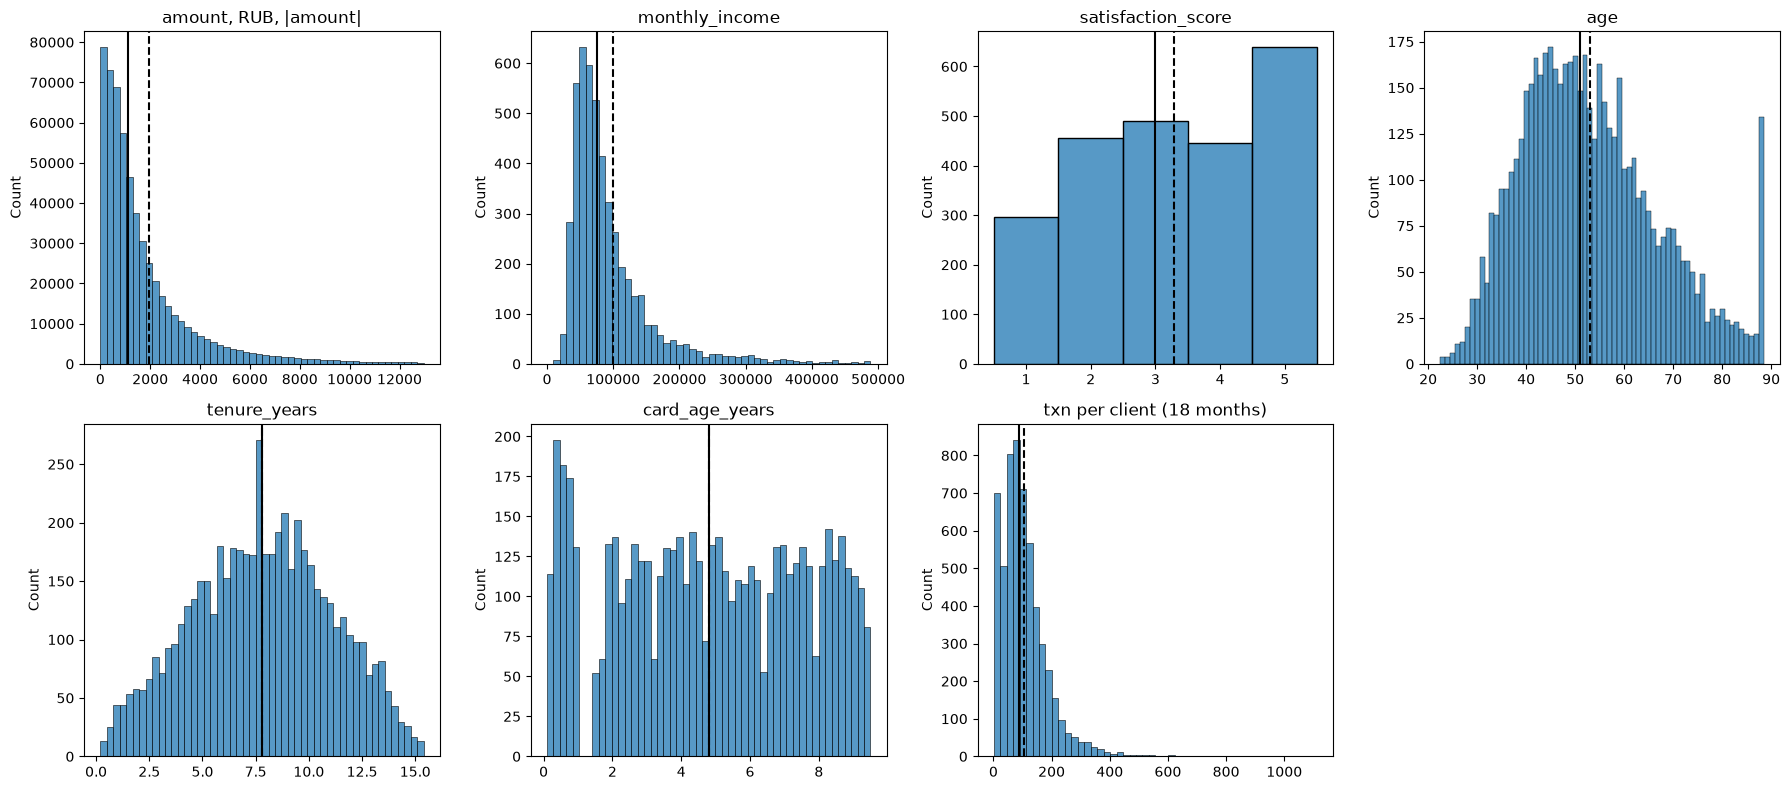

In [54]:
# распределения: сплошная линия - медиана, пунктир - среднее
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, s) in zip(axes.flatten(), features.items()):
    if name in ["amount, RUB, |amount|", "monthly_income"]:
        # длинный хвост (3.4) - столбики до 99-го процентиля, иначе все сжимается у нуля
        sns.histplot(s, bins=50, binrange=(0, s.quantile(0.99)), ax=ax)
    elif name in ["satisfaction_score", "age"]:
        # целые значения - по столбику на каждое
        sns.histplot(s, discrete=True, ax=ax)
    else:
        sns.histplot(s, bins=50, ax=ax)
    ax.axvline(s.median(), color="black")
    ax.axvline(s.mean(), color="black", ls="--")
    ax.set_title(name)
    ax.set_xlabel("")
axes[1, 3].axis("off")
plt.tight_layout()
plt.show()

у ```amount```, дохода и числа операций длинный правый хвост, медиана левее среднего; ```tenure_years``` симметричный; у ```satisfaction_score``` чаще всего ставят 5, реже всего 1. Две странности: у ```age``` отдельный пик на максимальном возрасте, в несколько раз выше соседних столбиков, а у ```card_age_years``` пусто примерно между 1.1 и 1.4 года и всплеск меньше 1 года - проверяем ниже

In [55]:
# пик на максимальном возрасте: одна и та же дата рождения?
print(f"age == {clients['age'].max()}: {(clients['age'] == clients['age'].max()).sum()} of {clients.shape[0]}")
print(clients["birth_date"].value_counts().head(3))
print()

# провал в возрасте карты: сколько карт открыто по месяцам за последние 2 года
print(clients["card_open_date"].dt.to_period("M").value_counts().sort_index()["2023-07":])

age == 88: 134 of 5612
birth_date
1965-10-12    5
1968-07-01    4
1976-10-23    4
Name: count, dtype: int64

card_open_date
2023-07    68
2023-08    52
2023-09    58
2023-10    50
2023-11    45
2023-12    17
2024-07    74
2024-08    85
2024-09    57
2024-10    78
2024-11    75
2024-12    79
2025-01    83
2025-02    79
2025-03    76
2025-04    71
2025-05    42
Freq: M, Name: count, dtype: int64


на максимальном возрасте 88 лет - 134 клиента из 5612 (2.388%). Возраст берется из ```birth_date```, значит пик в исходных датах: у 134 клиентов дата рождения попадает в один и тот же год - от минимальной 1936-07-24 (2.3) до 1937-06-30. При этом даты у них разные, т.е. это не одна дата-заглушка. Похоже, что в источнике дату рождения ограничили снизу: всем, кто старше, записали дату в этом году, и реальный возраст у них может быть больше 88. Для анализа это не мешает, если возраст брать группами ("80+"), но среднее и максимум возраста занижены

в первом полугодии 2024 не открыто ни одной карты, в 2023-12 всего 17 против 45-68 в остальные месяцы 2023, а с 2024-07 открывают по 71-85 в месяц (2025-05 неполный, 42) - больше, чем в 2023. Похоже на паузу в выпуске карт и догоняющий выпуск после нее. С 2024-07 по 2025-05 новую карту получили 799 клиентов из 5612 (14.237%)

### 5.2. Частотные характеристики категориальных признаков

                n       %
segment                  
Массовый     2906  51.782
Зарплатный   1540  27.441
Премиальный   917  16.340
Private       236   4.205
NaN            13   0.232 

                 n       %
loyalty_tier              
Базовый       2909  51.835
Серебро       1472  26.230
Золото         933  16.625
Платина        298   5.310 

                n       %
card_type                
Дебетовая    3902  69.530
Кредитная    1231  21.935
Премиальная   479   8.535 

                    n       %
city                         
Москва           1620  28.867
Санкт-Петербург   958  17.071
Казань            947  16.875
Екатеринбург      709  12.634
Нижний Новгород   688  12.259
Новосибирск       679  12.099
NaN                11   0.196 

           n       %
gender              
Ж       2830  50.428
М       2782  49.572 

                            n       %
income_source                        
Зарплата в нашем банке   2524  44.975
Не указан                1587  28.279
Зарплата в

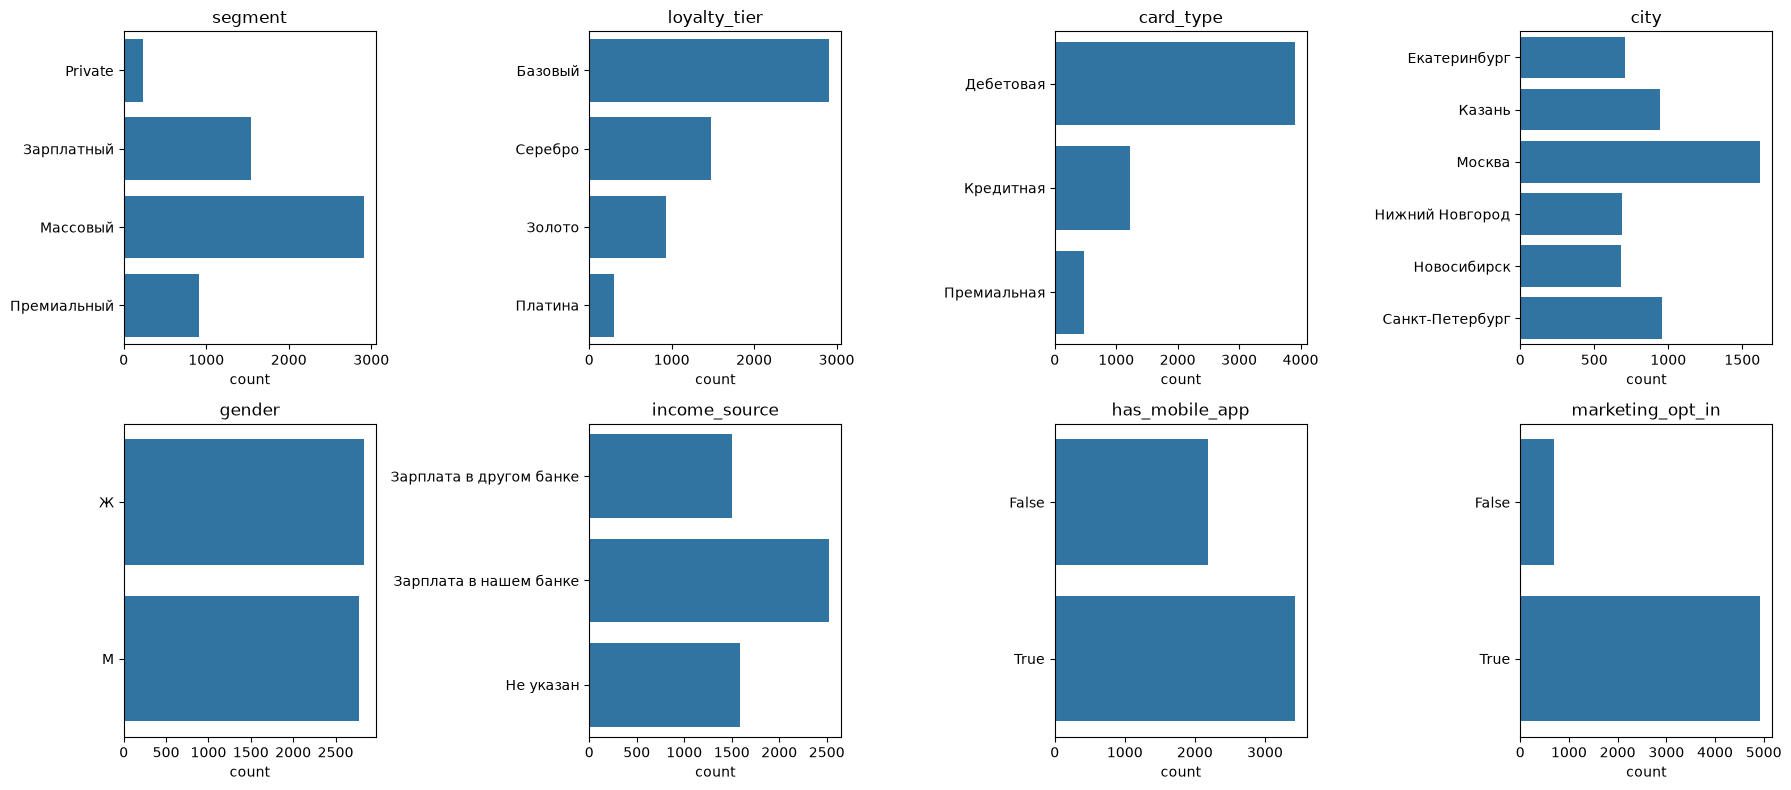

In [56]:
# частоты категориальных признаков клиентов (из 5612)
CLIENT_CAT = ["segment", "loyalty_tier", "card_type", "city", "gender", "income_source", "has_mobile_app", "marketing_opt_in"]
for col in CLIENT_CAT:
    vc = clients[col].value_counts(dropna=False)
    print(pd.DataFrame({"n": vc, "%": (vc / clients.shape[0] * 100).round(3)}), "\n")

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), CLIENT_CAT):
    sns.countplot(data=clients, y=col, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

половина клиентов - массовый сегмент (2906 из 5612, 51.782%) и базовый уровень лояльности (2909, 51.835%), доли сегментов и уровней лояльности почти совпадают - проверим связь в 5.4. Самые маленькие группы - Private (236, 4.205%), Платина (298, 5.310%) и премиальная карта (479, 8.535%): группа в кампанию должна быть от 150 человек, поэтому правило только по ним может не набрать размер. Москва - 28.867%, остальные города по 12-17%. Пол поровну (50.428% и 49.572%). Приложение есть у 60.976%, согласие на коммуникацию - у 87.758% (4925 из 5612)

                          n       %
category                           
Продукты             152527  26.083
Кафе и рестораны      75921  12.983
Транспорт             61079  10.445
Одежда и обувь        60830  10.402
АЗС                   54009   9.236
Развлечения и досуг   50837   8.693
Связь и интернет      45877   7.845
Аптеки                42751   7.311
Онлайн-сервисы        40940   7.001 

                  n       %
channel                    
Карта        300174  51.332
СБП           98765  16.890
Токен         97347  16.647
Онлайн-банк   88485  15.132 

                n       %
status                   
успешно    566032  96.795
отклонено   11789   2.016
возврат      6950   1.188 

               n       %
currency                
RUB       582382  99.591
USD         1199   0.205
EUR         1190   0.203 



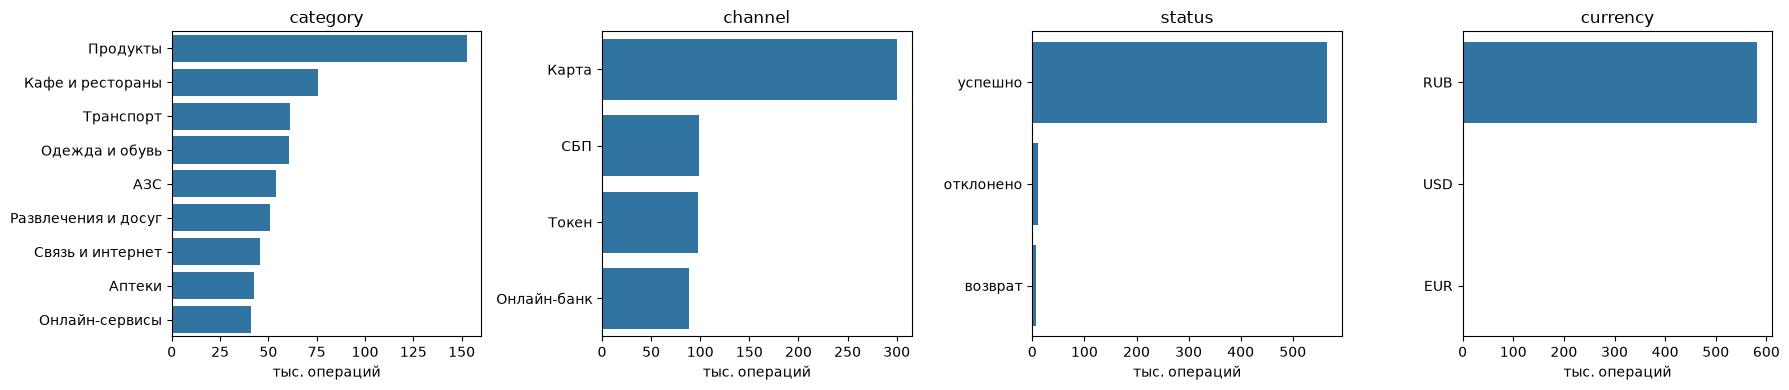

In [57]:
# частоты категориальных признаков операций (txn_f, из 584771)
TXN_CAT = ["category", "channel", "status", "currency"]
for col in TXN_CAT:
    vc = txn_f[col].value_counts()
    print(pd.DataFrame({"n": vc, "%": (vc / txn_f.shape[0] * 100).round(3)}), "\n")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, TXN_CAT):
    sns.countplot(data=txn_f, y=col, order=txn_f[col].value_counts().index, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(lambda v, pos: f"{v / 1000:.0f}")  # подписи в тысячах
    ax.set_xlabel("тыс. операций")
plt.tight_layout()
plt.show()

больше всего операций в продуктах (26.083% из 584771), остальные категории по 7-13%. Половина операций - картой (51.332%), СБП, токен и онлайн-банк примерно поровну (15-17%). Отклоненных 2.016%, возвратов 1.188%. Операций в USD и EUR 0.408% (0.205% + 0.203%)

### 5.3. Динамика по месяцам

In [58]:
# помесячно по txn_f: операции по статусам, клиенты с операциями
txn_f["month"] = txn_f["txn_datetime"].dt.to_period("M")
monthly = txn_f.groupby("month").agg(n_txn=("txn_id", "size"), n_clients=("client_id", "nunique"))
monthly = monthly.join(pd.crosstab(txn_f["month"], txn_f["status"]))
rub = txn_f[(txn_f["currency"] == "RUB") & (txn_f["status"] != "отклонено")]
monthly["sum_rub_mln"] = (rub.groupby("month")["amount"].sum() / 1e6).round(2)
monthly["txn_per_client"] = (monthly["n_txn"] / monthly["n_clients"]).round(1)
monthly

,n_txn,n_clients,возврат,отклонено,успешно,sum_rub_mln,txn_per_client
month,,,,,,,
2024-01,24836,4639,304,535,23997,46.34,5.4
2024-02,30850,4692,398,611,29841,57.97,6.6
2024-03,35319,4750,393,689,34237,65.78,7.4
2024-04,34572,4724,399,738,33435,64.09,7.3
2024-05,31915,4701,373,607,30935,58.85,6.8
2024-06,34135,4742,417,666,33052,63.03,7.2
2024-07,35163,4772,368,726,34069,64.49,7.4
2024-08,36203,4843,419,729,35055,66.24,7.5
2024-09,34824,4892,423,700,33701,64.80,7.1


в каждом месяце 2025 операций меньше, чем в том же месяце 2024 (январь 22882 против 24836, июнь 30954 против 34135). Есть сезонность: январь - минимум года, декабрь - максимум (44449 в 2024-12). Клиентов с операциями при этом не меньше: в 2024 их число росло с 4639 до 5122, в 2025 держится на 4786-5099

In [59]:
# среднее в месяц: весь 2024, те же месяцы 2024 (январь-июнь, без влияния сезона) и январь-июнь 2025
year_2024 = monthly.loc["2024-01":"2024-12"].mean()
h1_2024 = monthly.loc["2024-01":"2024-06"].mean()
h1_2025 = monthly.loc["2025-01":"2025-06"].mean()
pd.DataFrame({
    "2024": year_2024.round(1),
    "2024-01..06": h1_2024.round(1),
    "2025-01..06": h1_2025.round(1),
    "2025 vs 2024, %": ((h1_2025 / year_2024 - 1) * 100).round(1),
    "2025 vs 2024-01..06, %": ((h1_2025 / h1_2024 - 1) * 100).round(1),
})

,2024,2024-01..06,2025-01..06,"2025 vs 2024, %","2025 vs 2024-01..06, %"
n_txn,34467.5,31937.8,28526.8,-17.2,-10.7
n_clients,4821.2,4708.0,4948.3,2.6,5.1
возврат,408.6,380.7,341.2,-16.5,-10.4
отклонено,697.2,641.0,570.5,-18.2,-11.0
успешно,33361.8,30916.2,27615.2,-17.2,-10.7
sum_rub_mln,63.9,59.3,49.5,-22.6,-16.6
txn_per_client,7.1,6.8,5.8,-19.3,-15.0


сравнение со средним за весь 2024 завышает падение из-за сезона: во втором полугодии и особенно в декабре операций больше, поэтому к 2024 целиком выходит -17.2%, а к тем же месяцам 2024 - только -10.7%. Это нужно учесть при выборе метрики в главе 6

к январю-июню 2024: операций в месяц меньше на 10.7%, суммы в рублях - на 16.6%, а клиентов с операциями в месяц больше на 5.1%. Т.е. падение не за счет того, что клиенты пропали, а за счет того, что каждый делает меньше операций (6.8 -> 5.8 в месяц, -15.0%). Отклоненные и возвраты упали так же, как успешные (-11.0% и -10.4% против -10.7%), их доля не изменилась

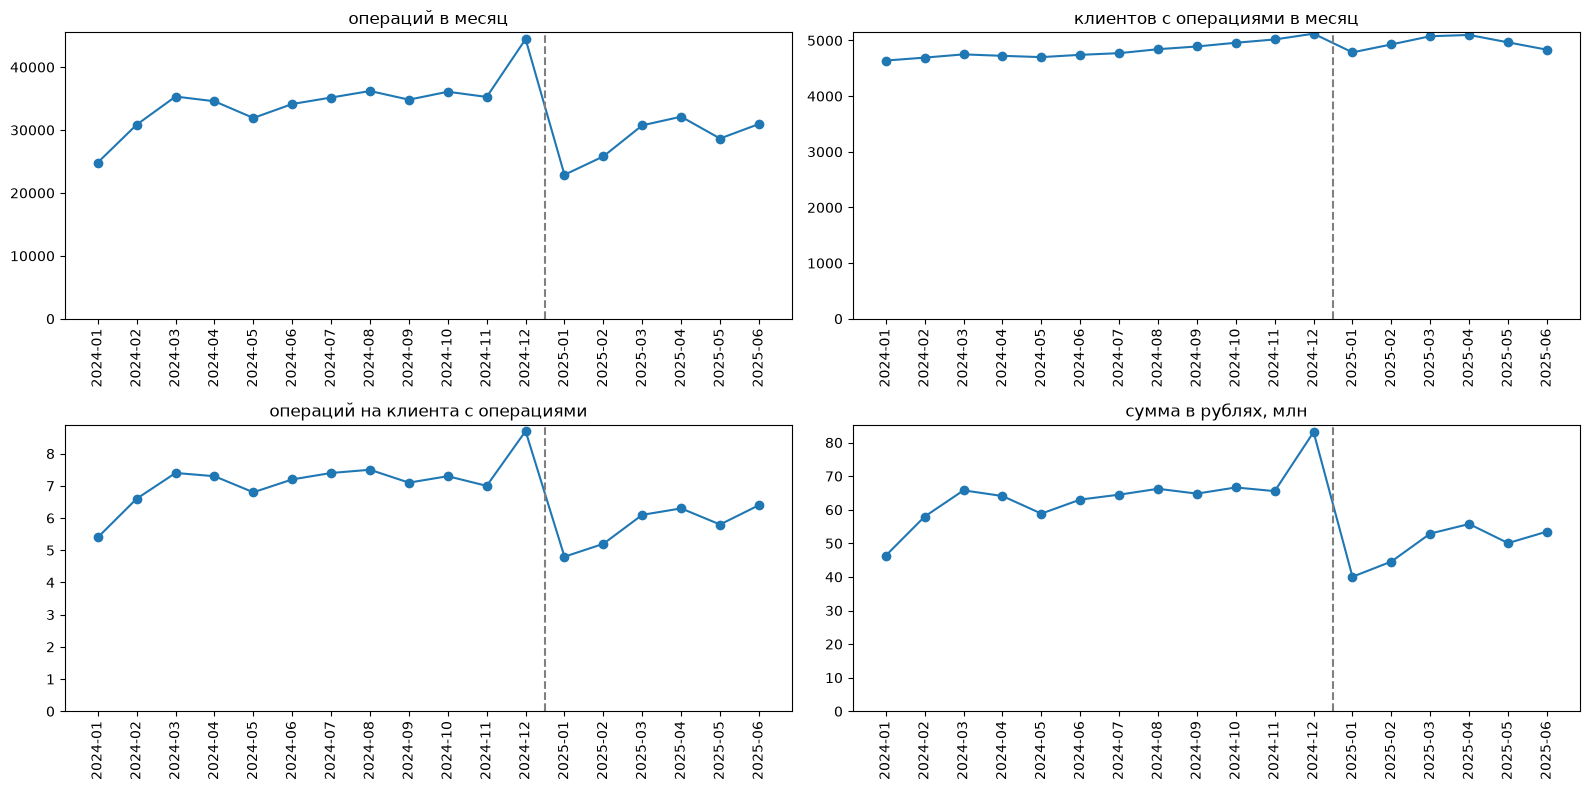

In [60]:
# динамика по месяцам, пунктир - граница 2024 / 2025
x = monthly.index.astype(str)
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
panels = [("n_txn", "операций в месяц"), ("n_clients", "клиентов с операциями в месяц"),
          ("txn_per_client", "операций на клиента с операциями"), ("sum_rub_mln", "сумма в рублях, млн")]
for ax, (col, title) in zip(axes.flatten(), panels):
    ax.plot(x, monthly[col], marker="o")
    ax.axvline(11.5, color="gray", ls="--")
    ax.set_title(title)
    ax.set_ylim(0, None)
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

на всех графиках, кроме числа клиентов, разрыв на границе 2024/2025: декабрьский пик и январский провал, дальше 2025 растет, но остается ниже 2024

### 5.4. Разрезы и связи между признаками

сравниваем январь-июнь 2025 с январем-июнем 2024 (одни и те же месяцы, без влияния сезона, см. 5.3): число операций клиента в месяц, без возвратов (возврат - отмена покупки, а не новая операция). Берем только клиентов, у которых текущая карта открыта до 2024: операции в данных начинаются с открытия карты (проверка ниже), и у остальных январь-июнь 2024 пустой. Изменение группы считаем по средним за месяц (это то же, что по сумме операций группы): медиана изменений по клиентам не считается у тех, у кого в 2024 было 0 операций

In [61]:
# у клиентов с новой картой (с 2024-07) в январе-июне 2024 нет ни одной операции - операции начинаются с открытия текущей карты?
first = txn_f.groupby("client_id")["txn_datetime"].min()
card = clients.set_index("client_id")["card_open_date"].reindex(first.index)
print(f"clients with txn before card_open_date: {(first < card).sum()} of {first.shape[0]}")
print(((first - card).dt.days).describe().round(1))

clients with txn before card_open_date: 0 of 5605
count    5605.0
mean     1267.3
std       925.8
min         0.0
25%       404.0
50%      1212.0
75%      2094.0
max      2940.0
dtype: float64


операций раньше открытия текущей карты нет ни у одного клиента (0 из 5605), т.е. в ```txn``` только операции по текущей карте. Поэтому у клиентов с картой, открытой с 2024-07, январь-июнь 2024 пустой не потому, что они не пользовались картой, а потому, что карты еще не было. Для сравнения ниже берем только клиентов с картой до 2024, а в главе 6 базовый период клиента должен начинаться не раньше открытия карты

In [62]:
# операций клиента в месяц: январь-июнь 2024 и январь-июнь 2025, без возвратов
ops = txn_f[txn_f["status"] != "возврат"]
h1_24 = ops[(ops["txn_datetime"] >= "2024-01-01") & (ops["txn_datetime"] < "2024-07-01")].groupby("client_id").size() / 6
h1_25 = ops[(ops["txn_datetime"] >= "2025-01-01") & (ops["txn_datetime"] < "2025-07-01")].groupby("client_id").size() / 6

base = clients[clients["card_open_date"] < "2024-01-01"].set_index("client_id")
base["ops_24"] = h1_24.reindex(base.index, fill_value=0)
base["ops_25"] = h1_25.reindex(base.index, fill_value=0)

base["age_group"] = pd.cut(base["age"], bins=[0, 30, 40, 50, 60, 70, 80, 200], right=False,
                           labels=["<30", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])
base["new_card"] = base["card_open_date"] >= "2024-07-01"

print(f"clients with card opened before 2024: {base.shape[0]} of {clients.shape[0]}")
print(f"ops per month: 2024-01..06 {base['ops_24'].mean():.2f} | 2025-01..06 {base['ops_25'].mean():.2f} | change {(base['ops_25'].mean() / base['ops_24'].mean() - 1) * 100:.1f}%")

clients with card opened before 2024: 4813 of 5612
ops per month: 2024-01..06 6.56 | 2025-01..06 5.59 | change -14.7%


карта открыта до 2024 у 4813 из 5612 клиентов, у них операций в месяц 6.56 в январе-июне 2024 и 5.59 в январе-июне 2025 (-14.7%)

In [63]:
# изменение операций в месяц по разрезам клиентов
SLICES = ["segment", "loyalty_tier", "card_type", "city", "age_group", "gender", "income_source", "has_mobile_app", "marketing_opt_in"]
for col in SLICES:
    g = base.groupby(col, observed=True).agg(n=("ops_24", "size"), ops_24=("ops_24", "mean"), ops_25=("ops_25", "mean"))
    g["change %"] = ((g["ops_25"] / g["ops_24"] - 1) * 100).round(1)
    print(g.round(2), "\n")

                n  ops_24  ops_25  change %
segment                                    
Private       201    8.24    7.53      -8.7
Зарплатный   1274    7.22    7.14      -1.2
Массовый     2573    5.63    4.00     -28.9
Премиальный   753    8.15    7.90      -3.1 

                 n  ops_24  ops_25  change %
loyalty_tier                                
Базовый       2533    6.14    4.85     -20.9
Серебро       1244    6.88    5.99     -13.0
Золото         787    7.16    6.92      -3.3
Платина        249    7.31    6.90      -5.6 

                n  ops_24  ops_25  change %
card_type                                  
Дебетовая    3378    6.32    5.27     -16.5
Кредитная    1052    6.92    6.06     -12.5
Премиальная   383    7.66    7.12      -7.0 

                    n  ops_24  ops_25  change %
city                                           
Екатеринбург      603    6.70    5.85     -12.7
Казань            827    6.08    4.58     -24.7
Москва           1392    6.74    5.88     -12.8


падение почти целиком у массового сегмента: -28.9% (2573 клиента), у остальных сегментов от -1.2% до -8.7%. Сильнее среднего (-14.7%) падают также клиенты без приложения (-22.9%, 1919 клиентов против -9.7% с приложением), старшие (от -16.3% в 50-59 до -22.5% в 70-79, у 30-39 только -8.2%), с зарплатой в другом банке (-20.2%) или без указанного источника (-20.7%) против -8.4% с зарплатой в нашем банке, и Казань (-24.7% при -11.4% - -14.0% в остальных городах). Базовый уровень лояльности (-20.9%) и дебетовая карта (-16.5%) повторяют массовый сегмент. Пол и согласие на коммуникацию почти не влияют (-16.0% и -13.4%, -16.0% и -14.5%)

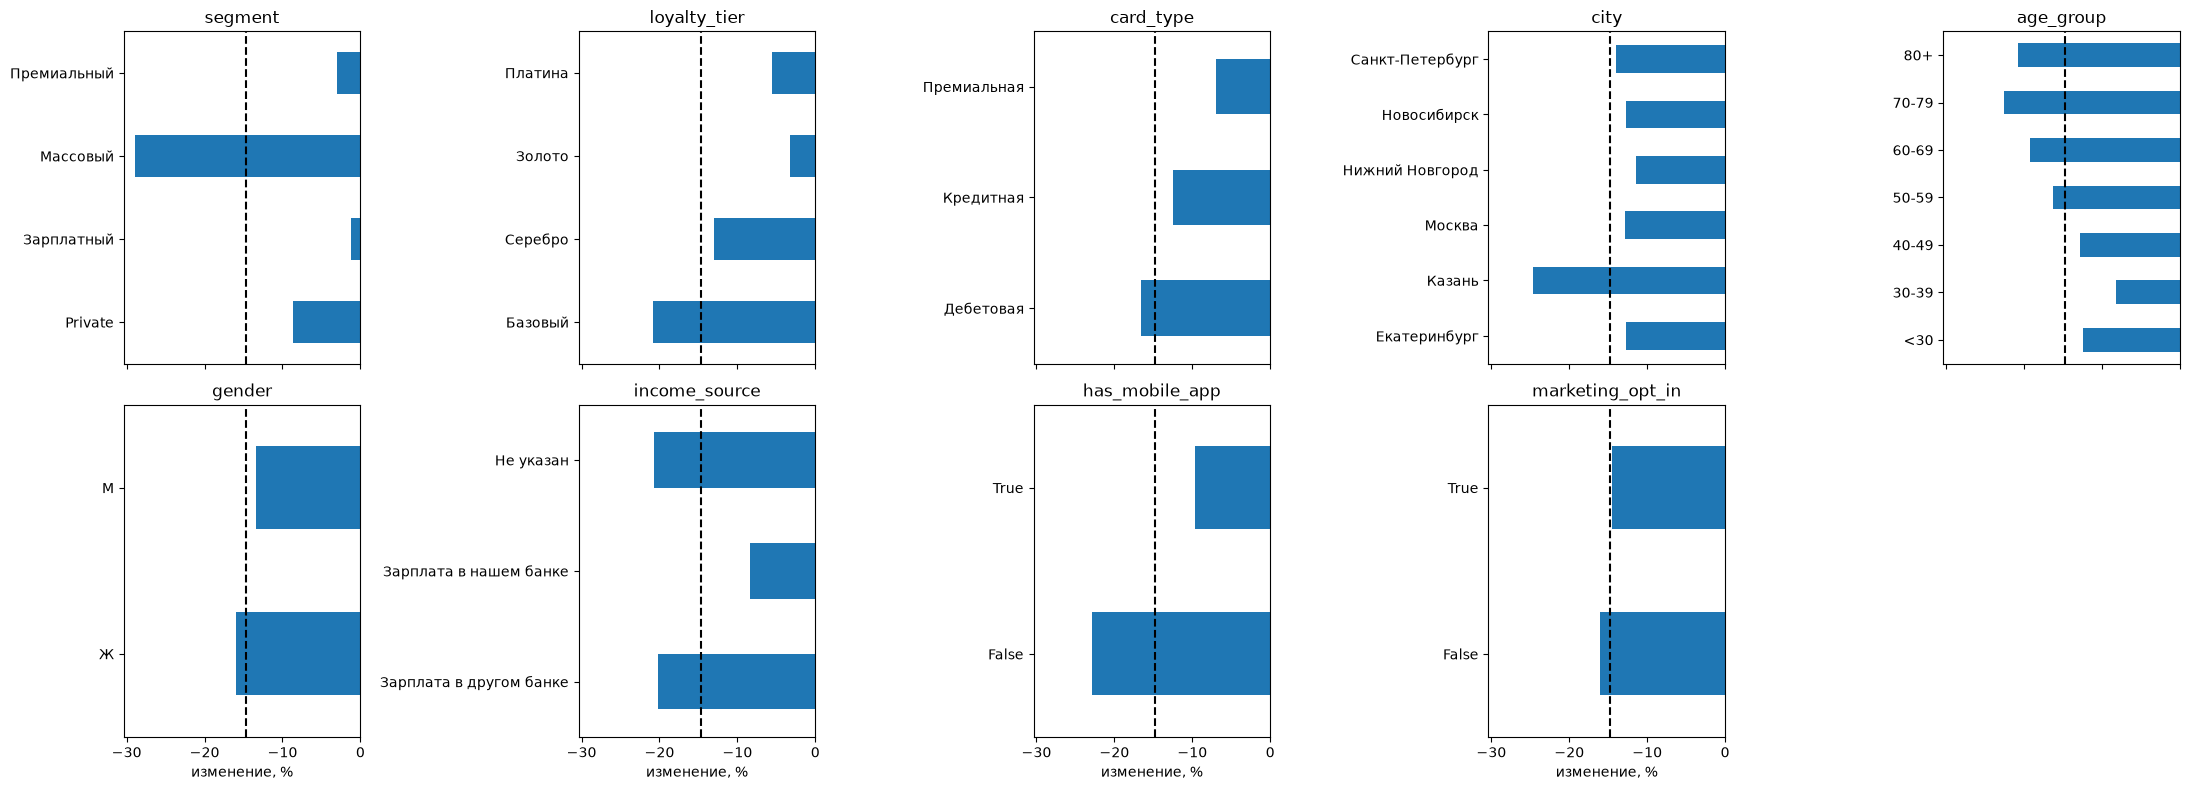

In [64]:
# изменение, %, по разрезам; пунктир - изменение по всем клиентам
total = (base["ops_25"].mean() / base["ops_24"].mean() - 1) * 100
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharex=True)
for ax, col in zip(axes.flatten(), SLICES):
    g = base.groupby(col, observed=True)[["ops_24", "ops_25"]].mean()
    ((g["ops_25"] / g["ops_24"] - 1) * 100).plot.barh(ax=ax)
    ax.axvline(total, color="black", ls="--")
    ax.set_title(col)
    ax.set_ylabel("")
    ax.set_xlabel("изменение, %")
axes[1, 4].axis("off")
plt.tight_layout()
plt.show()

графики повторяют таблицу выше: левее пунктира (в среднем -14.7%) - массовый сегмент, базовая лояльность, дебетовая карта, Казань, возраст от 50, без приложения, зарплата не в нашем банке или не указана. Ближе всего к нулю - зарплатный и премиальный сегменты, золото и платина, возраст 30-39. По полу и согласию на коммуникацию группы почти не отличаются от среднего

In [65]:
# изменение числа операций по каналам и категориям (те же клиенты, январь-июнь)
h1 = ops[ops["client_id"].isin(base.index) & (ops["txn_datetime"].dt.month <= 6)]
for col in ["channel", "category"]:
    t = pd.crosstab(h1[col], h1["txn_datetime"].dt.year)
    t["change %"] = ((t[2025] / t[2024] - 1) * 100).round(1)
    print(t.sort_values("change %"), "\n")

txn_datetime    2024   2025  change %
channel                              
СБП            33273  24432     -26.6
Карта         100958  74573     -26.1
Онлайн-банк    28608  24597     -14.0
Токен          26504  37869      42.9 

txn_datetime          2024   2025  change %
category                                   
Развлечения и досуг  17405  11749     -32.5
Аптеки               13858  11766     -15.1
Продукты             49351  42179     -14.5
Транспорт            19723  16963     -14.0
Связь и интернет     14834  12891     -13.1
Онлайн-сервисы       13160  11431     -13.1
Одежда и обувь       19463  17301     -11.1
АЗС                  17275  15444     -10.6
Кафе и рестораны     24274  21747     -10.4 



растет только оплата токеном (+42.9%), все остальные каналы падают: карта -26.1%, СБП -26.6%, онлайн-банк -14.0%. Т.е. это не простой переход с карты на телефон - СБП тоже оплата телефоном, а падает так же, как карта. Переходят ли на токен те же клиенты, у которых упали карта и СБП, проверим при поиске групп. По категориям сильнее всего упали развлечения (-32.5%), остальные от -10.4% до -15.1%

In [66]:
# связь сегмента и уровня лояльности (доли внутри сегмента)
print(pd.crosstab(clients["segment"], clients["loyalty_tier"], normalize="index").round(3))

loyalty_tier  Базовый  Серебро  Золото  Платина
segment                                        
Private         0.017    0.072   0.403    0.508
Зарплатный      0.484    0.318   0.175    0.024
Массовый        0.708    0.216   0.065    0.011
Премиальный     0.104    0.364   0.414    0.118


сегмент и лояльность связаны, но не дублируют друг друга: массовые в основном на базовом уровне (70.8%), Private - на золоте и платине (40.3% + 50.8% = 91.1%), а у зарплатных и премиальных уровни разбросаны (премиальные: серебро 36.4%, золото 41.4%, базовый 10.4%, платина 11.8%). Поэтому в группах лояльность может уточнять сегмент, это проверим в главе 7

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

операции в ```txn``` начинаются с открытия текущей карты (5.4), поэтому у клиентов с картой, открытой в 2024, базовый период короче 12 месяцев. Чтобы выбрать, сколько месяцев карты в 2024 нужно для надежной базы, смотрим, отличаются ли первые месяцы после открытия карты от обычного уровня клиента

In [67]:
# операции в k-й месяц после открытия карты (k = 0 - месяц открытия) относительно медианы клиента
new = clients[clients["card_open_date"] >= "2024-07-01"].set_index("client_id")
counts = pd.crosstab(txn_f["client_id"], txn_f["month"]).reindex(new.index, fill_value=0)
long = counts.stack().rename("n").reset_index()

open_m = long["client_id"].map(new["card_open_date"]).dt.to_period("M")
long["k"] = (long["month"].dt.year * 12 + long["month"].dt.month) - (open_m.dt.year * 12 + open_m.dt.month)
long = long[long["k"] >= 0]

med = long.groupby("client_id")["n"].median()
long = long[long["client_id"].map(med) > 0]
long["ratio"] = long["n"] / long["client_id"].map(med)

print(f"clients with card opened 2024-07 - 2025-05: {new.shape[0]} | with median > 0: {long['client_id'].nunique()}")
ramp = long.groupby("k")["ratio"].agg(["count", "median", "mean"]).round(2)
ramp

clients with card opened 2024-07 - 2025-05: 799 | with median > 0: 697


,count,median,mean
k,,,
0,697,0.0,0.5
1,697,1.0,1.25
2,658,1.0,1.3
3,603,1.0,1.27
4,538,1.0,1.29
5,477,1.0,1.18
6,398,1.0,1.07
7,333,1.0,1.17
8,263,1.0,1.29


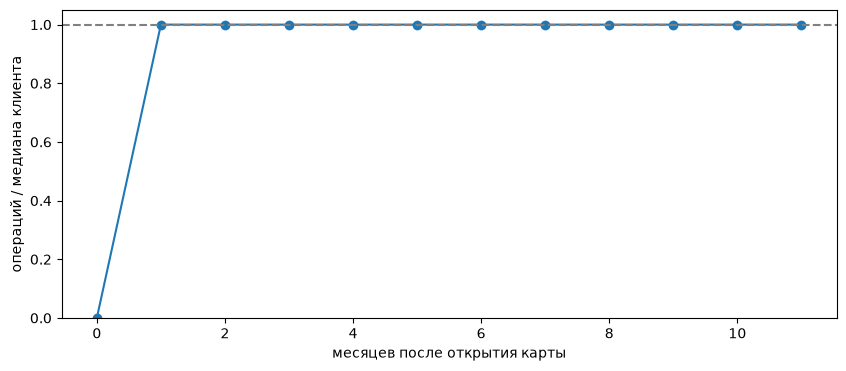

In [68]:
# медиана отношения по месяцам после открытия; 1 - обычный уровень клиента
ax = ramp["median"].plot(marker="o", figsize=(10, 4))
ax.axhline(1, color="gray", ls="--")
ax.set_xlabel("месяцев после открытия карты")
ax.set_ylabel("операций / медиана клиента")
ax.set_ylim(0, None)
plt.show()

разгона после открытия карты нет: ниже обычного только сам месяц открытия (k = 0, медиана 0, среднее 0.50) - он неполный, карту открывают посреди месяца. С первого полного месяца уровень обычный и дальше не меняется: медиана ровно 1.0 при всех k (операций в месяц - целые числа и часто совпадают с медианой клиента), среднее 1.07-1.30 без тренда (среднее отношения выше 1 из-за правого хвоста). У 102 из 799 клиентов медиана 0 - большую часть месяцев операций нет, их отношение не считается

значит, базовый период клиента начинается с первого полного месяца после открытия карты

метрика - число операций клиента по карте в месяц (частота: заказчик видит, что карты стали использовать реже). Отклоненные операции считаем - это попытка воспользоваться картой. Считаем в двух вариантах, с возвратами и без, и проверяем, что выводы от этого не зависят

- база: среднее операций в месяц за 2024, начиная с первого полного месяца после открытия карты (до открытия операций нет - 5.4, месяц открытия неполный - выше)
- оцениваемый период: среднее за январь - июнь 2025
- изменение клиента: оцениваемый период / база - 1

в расчет берем клиентов, у которых в 2024 не меньше 3 полных месяцев карты (карта открыта до 2024-09 включительно): если база из 1-2 месяцев, в ней почти только декабрь - пик года (5.3), и падение выходит завышенным

In [69]:
# сколько полных месяцев карты в базовом периоде (2024) у каждого клиента
m = clients.set_index("client_id")
first_full = m["card_open_date"].dt.to_period("M") + 1
start_idx = (first_full.dt.year * 12 + first_full.dt.month).clip(lower=2024 * 12 + 1)
m["base_months"] = 2024 * 12 + 12 - start_idx + 1

print(f"clients: {m.shape[0]}")
print(f"no full month in 2024 (card opened 2024-12 or later): {(m['base_months'] <= 0).sum()}")
print(f"base 1-2 months (card opened 2024-10, 2024-11): {m['base_months'].between(1, 2).sum()}")
print(f"base 3+ months: {(m['base_months'] >= 3).sum()} (of them full 12 months: {(m['base_months'] == 12).sum()})")

clients: 5612
no full month in 2024 (card opened 2024-12 or later): 430
base 1-2 months (card opened 2024-10, 2024-11): 153
base 3+ months: 5029 (of them full 12 months: 4813)


в расчете 5029 из 5612 клиентов: 4813 с полным 2024 и 216 с картой, открытой в 2024-07 - 2024-09. Без расчета 430 клиентов без полного месяца карты в 2024 (карта открыта с 2024-12) и 153 с базой 1-2 месяца (карта 2024-10, 2024-11) - они идут в 7.1

In [70]:
# операций в месяц: база и оцениваемый период, с возвратами (all) и без (nr)
month_idx = txn_f["month"].dt.year * 12 + txn_f["month"].dt.month
in_base = (month_idx >= txn_f["client_id"].map(start_idx)) & (txn_f["month"].dt.year == 2024)
in_eval = txn_f["month"].dt.year == 2025
not_return = txn_f["status"] != "возврат"

m["base_all"] = txn_f[in_base].groupby("client_id").size().reindex(m.index, fill_value=0) / m["base_months"]
m["eval_all"] = txn_f[in_eval].groupby("client_id").size().reindex(m.index, fill_value=0) / 6
m["base_nr"] = txn_f[in_base & not_return].groupby("client_id").size().reindex(m.index, fill_value=0) / m["base_months"]
m["eval_nr"] = txn_f[in_eval & not_return].groupby("client_id").size().reindex(m.index, fill_value=0) / 6

metric = m[(m["base_months"] >= 3) & (m["base_all"] > 0)].copy()
metric["change_all"] = metric["eval_all"] / metric["base_all"] - 1
metric["change_nr"] = metric["eval_nr"] / metric["base_nr"] - 1

print(f"in metric: {metric.shape[0]} | base 3+ months but 0 operations in base: {((m['base_months'] >= 3) & (m['base_all'] == 0)).sum()}")
print(metric[["base_all", "eval_all", "change_all", "base_nr", "eval_nr", "change_nr"]].describe().round(3))

# с возвратами и без - один и тот же порядок клиентов? Спирмен (по рангам, хвост не мешает) и Пирсон для сравнения
print(f"\nchange_all vs change_nr: Spearman {metric['change_all'].corr(metric['change_nr'], method='spearman'):.3f} | Pearson {metric['change_all'].corr(metric['change_nr']):.3f}")
print(f"max |change_all - change_nr|: {(metric['change_all'] - metric['change_nr']).abs().max():.3f}")

in metric: 5029 | base 3+ months but 0 operations in base: 0
       base_all  eval_all  change_all   base_nr   eval_nr  change_nr
count  5029.000  5029.000    5029.000  5029.000  5029.000   5029.000
mean      6.905     5.499      -0.216     6.824     5.434     -0.216
std       4.424     4.816       0.384     4.373     4.758      0.384
min       0.333     0.000      -1.000     0.333     0.000     -1.000
25%       3.917     2.167      -0.535     3.917     2.167     -0.536
50%       5.917     4.167      -0.210     5.833     4.167     -0.208
75%       8.667     7.333       0.017     8.583     7.333      0.018
max      58.000    69.500       3.333    57.500    69.167      3.333

change_all vs change_nr: Spearman 0.998 | Pearson 0.998
max |change_all - change_nr|: 0.250


у половины клиентов операций в месяц стало меньше на 21% и больше (медиана -0.210), у четверти - на 53.5% и больше (25-й процентиль -0.535), у четверти - не меньше, чем было (75-й процентиль 0.017). Клиентов с базой, но без операций в базе нет (0)

с возвратами и без метрика почти одна и та же: Спирмен 0.998, Пирсон 0.998, медиана -0.210 и -0.208. Поэтому считаем с возвратами - все операции по карте, без исключений (```change_all```). Спирмен основной: он сравнивает порядок клиентов и не зависит от хвоста, Пирсон для сравнения

In [71]:
# сезонность: то же изменение, но к январю-июню 2024 (только клиенты с картой до 2024, у них эти месяцы есть)
full = metric[metric["base_months"] == 12].copy()
h1 = txn_f["month"].dt.year.eq(2024) & txn_f["month"].dt.month.le(6)
full["h1_all"] = txn_f[h1].groupby("client_id").size().reindex(full.index, fill_value=0) / 6
full = full[full["h1_all"] > 0]
full["change_h1"] = full["eval_all"] / full["h1_all"] - 1

print(f"clients: {full.shape[0]}")
print(f"median change: vs 2024 {full['change_all'].median():.3f} | vs 2024-01..06 {full['change_h1'].median():.3f}")
print(f"Spearman change_all vs change_h1: {full['change_all'].corr(full['change_h1'], method='spearman'):.3f} | Pearson {full['change_all'].corr(full['change_h1']):.3f}")

clients: 4813
median change: vs 2024 -0.212 | vs 2024-01..06 -0.148
Spearman change_all vs change_h1: 0.958 | Pearson 0.936


к тем же месяцам 2024 падение меньше (медиана -0.148 против -0.212) - это сезон, во втором полугодии 2024 операций больше (5.3). Но порядок клиентов почти тот же: Спирмен 0.958. Т.е. база по заданию (весь 2024) сдвигает всех примерно одинаково, кто снизился сильнее других - не меняется

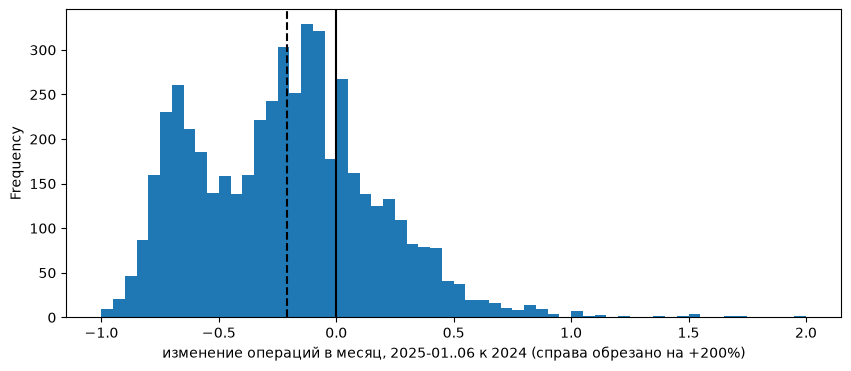

In [72]:
# распределение изменения по клиентам; 0 - без изменений, -1 - операций в 2025 нет совсем
ax = metric["change_all"].clip(upper=2).plot.hist(bins=60, figsize=(10, 4))
ax.axvline(0, color="black")
ax.axvline(metric["change_all"].median(), color="black", ls="--")
ax.set_xlabel("изменение операций в месяц, 2025-01..06 к 2024 (справа обрезано на +200%)")
plt.show()

распределение двугорбое: один пик около -0.7 (операций стало примерно на 70% меньше), второй около -0.1 (почти без изменений), между ними провал. Т.е. снизившие - не хвост общего распределения, а отдельная часть клиентов. Порог "снизил" берем по провалу (ниже)

In [73]:
# где провал между пиками: число клиентов по интервалам изменения шириной 0.05
print(pd.cut(metric["change_all"], bins=np.arange(-1, 0.01, 0.05), include_lowest=True).value_counts().sort_index())

change_all
(-1.001, -0.95]       10
(-0.95, -0.9]         21
(-0.9, -0.85]         45
(-0.85, -0.8]         98
(-0.8, -0.75]        162
(-0.75, -0.7]        229
(-0.7, -0.65]        251
(-0.65, -0.6]        227
(-0.6, -0.55]        170
(-0.55, -0.5]        171
(-0.5, -0.45]        124
(-0.45, -0.4]        138
(-0.4, -0.35]        160
(-0.35, -0.3]        223
(-0.3, -0.25]        268
(-0.25, -0.2]        296
(-0.2, -0.15]        232
(-0.15, -0.1]        332
(-0.1, -0.05]        318
(-0.05, 8.88e-16]    257
Name: count, dtype: int64


левый пик - интервал от -0.7 до -0.65 (251 клиент), правый - от -0.15 до -0.1 (332), самое низкое место между ними - от -0.5 до -0.45 (124). Порог "снизил" ставим на провал: изменение -0.45 и сильнее, т.е. операций в месяц стало меньше хотя бы на 45%. Провал неглубокий (124 против 251 и 332), поэтому в главе 7 проверим, что группы не меняются при пороге -0.4 и -0.5

In [74]:
# снизившие: операций в месяц стало меньше на 45% и больше
DROP = -0.45
metric["dropped"] = metric["change_all"] <= DROP
print(f"dropped: {metric['dropped'].sum()} of {metric.shape[0]} ({metric['dropped'].mean() * 100:.3f}%)")
print(f"dropped with marketing_opt_in: {(metric['dropped'] & metric['marketing_opt_in']).sum()}")

dropped: 1508 of 5029 (29.986%)
dropped with marketing_opt_in: 1322


снизили операции на 45% и больше 1508 из 5029 клиентов (29.986%), из них согласие на коммуникацию есть у 1322. Это меньше бюджета 2000, т.е. бюджет не ограничивает - вопрос в том, как разбить их на 3-5 групп по правилам "кто + что произошло"

что метрика не увидит: падение сумм при той же частоте (клиент платит так же часто, но меньше); перенос крупных трат в другой банк, если мелкие операции остались; падение только в последние месяцы (среднее за полгода его сглаживает); клиента с большим числом отклоненных операций - он выглядит активным, хотя картой фактически не может расплатиться; клиентов с картой, открытой после 2024-09, - у них нет надежной базы

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

группы ищем среди снизившихся (```dropped```, 6): сначала кто они - где доля снизившихся выше средних 29.986%, потом что с ними произошло - какие каналы и категории операций упали

In [75]:
# кто: доля снизившихся в разрезах (в среднем 1508 из 5029, 29.986%)
metric["age_group"] = pd.cut(metric["age"], bins=[0, 30, 40, 50, 60, 70, 80, 200], right=False,
                             labels=["<30", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])
WHO = ["segment", "loyalty_tier", "card_type", "city", "age_group", "gender", "income_source", "has_mobile_app", "marketing_opt_in"]
for col in WHO:
    g = metric.groupby(col, observed=True)["dropped"].agg(["size", "sum", "mean"])
    g.columns = ["n", "dropped", "dropped %"]
    g["dropped %"] = (g["dropped %"] * 100).round(1)
    print(g, "\n")

# сегмент и приложение вместе: доля снизившихся, % и число клиентов
print((pd.crosstab(metric["segment"], metric["has_mobile_app"], values=metric["dropped"], aggfunc="mean") * 100).round(1))
print(pd.crosstab(metric["segment"], metric["has_mobile_app"]))

                n  dropped  dropped %
segment                              
Private       214       27       12.6
Зарплатный   1345      196       14.6
Массовый     2658     1159       43.6
Премиальный   800      121       15.1 

                 n  dropped  dropped %
loyalty_tier                          
Базовый       2626      992       37.8
Серебро       1304      370       28.4
Золото         834      114       13.7
Платина        265       32       12.1 

                n  dropped  dropped %
card_type                            
Дебетовая    3510     1128       32.1
Кредитная    1107      308       27.8
Премиальная   412       72       17.5 

                    n  dropped  dropped %
city                                     
Екатеринбург      635      172       27.1
Казань            865      333       38.5
Москва           1450      423       29.2
Нижний Новгород   601      165       27.5
Новосибирск       609      158       25.9
Санкт-Петербург   858      252       29.4 

    

снизившиеся - это в первую очередь массовый сегмент: 43.6% массовых снизились против 12.6-15.1% в остальных сегментах, это 1159 из 1508 снизившихся (76.857%). Сильнее среднего (29.986%) также: без приложения (40.9%), базовый уровень лояльности (37.8%), Казань (38.5%), возраст 60+ (34.6-39.6%), зарплата в другом банке (34.2%) или не указана (37.5%). Пол и согласие почти не влияют

сегмент и приложение действуют вместе: у массовых без приложения снизились 58.8% (из 1047), у массовых с приложением - 33.7% (из 1611), а в остальных сегментах даже без приложения только 17.3-21.3%

In [76]:
# что произошло: операций в месяц по каналам и категориям, база и 2025, у снизившихся и остальных
def per_month(col):
    base_ = txn_f[in_base].groupby(["client_id", col], observed=True).size().unstack(fill_value=0)
    eval_ = txn_f[in_eval].groupby(["client_id", col], observed=True).size().unstack(fill_value=0)
    base_ = base_.reindex(metric.index, fill_value=0).div(metric["base_months"], axis=0)
    eval_ = eval_.reindex(metric.index, fill_value=0) / 6
    return base_, eval_

for col in ["channel", "category"]:
    base_, eval_ = per_month(col)
    for name, d in [("dropped", metric["dropped"]), ("not dropped", ~metric["dropped"])]:
        t = pd.DataFrame({"base": base_[d].mean(), "2025": eval_[d].mean()})
        t["change %"] = ((t["2025"] / t["base"] - 1) * 100).round(1)
        print(f"{col}, {name}")
        print(t.round(2).sort_values("change %"), "\n")

channel, dropped
             base  2025  change %
channel                          
СБП          1.14  0.33     -70.8
Карта        3.12  1.08     -65.5
Онлайн-банк  1.00  0.35     -64.6
Токен        0.79  0.30     -62.7 

channel, not dropped
             base  2025  change %
channel                          
Карта        3.92  3.17     -19.2
СБП          1.25  1.05     -16.0
Онлайн-банк  1.06  1.05      -1.5
Токен        1.04  1.71      64.6 

category, dropped
                     base  2025  change %
category                                 
Развлечения и досуг  0.47  0.13     -71.8
Продукты             1.69  0.57     -66.3
Одежда и обувь       0.59  0.20     -66.1
Аптеки               0.50  0.17     -66.0
Транспорт            0.68  0.23     -65.6
Онлайн-сервисы       0.43  0.15     -65.4
АЗС                  0.51  0.18     -64.8
Кафе и рестораны     0.69  0.24     -64.4
Связь и интернет     0.51  0.18     -63.7 

category, not dropped
                     base  2025  change %
cate

у снизившихся упало все примерно одинаково: каналы от -62.7% до -70.8%, категории от -63.7% до -71.8%. Т.е. они не ушли из какого-то одного канала или категории, а реже пользуются картой вообще. Токен у них тоже упал (-62.7%), а у остальных клиентов вырос на 64.6% при падении карты на 19.2% - переход с карты на токен идет у тех, кто не снизился. У остальных из категорий заметно упали только развлечения (-27.5%), прочие почти без изменений

значит, "что произошло" ищем не в каналах и категориях, а в том, как и когда упало: резко или постепенно, почти до нуля или наполовину, выросла ли доля отклоненных

In [77]:
# когда началось падение: операций в месяц относительно своей базы (1 - уровень базы), среднее по группе
# только клиенты с полным 2024, у остальных месяцы до открытия карты пустые
cnt = pd.crosstab(txn_f["client_id"], txn_f["month"]).reindex(metric.index, fill_value=0)
idx = cnt.div(metric["base_all"], axis=0)
full12 = metric["base_months"] == 12
mass = metric["segment"] == "Массовый"
groups = {
    "not dropped": ~metric["dropped"],
    "dropped": metric["dropped"],
    "dropped, mass, no app": metric["dropped"] & mass & ~metric["has_mobile_app"],
    "dropped, mass, app": metric["dropped"] & mass & metric["has_mobile_app"],
    "dropped, not mass": metric["dropped"] & ~mass,
    "dropped, Kazan": metric["dropped"] & (metric["city"] == "Казань"),
    "dropped, 60+": metric["dropped"] & (metric["age"] >= 60),
}
traj = pd.DataFrame({name: idx[mask & full12].mean() for name, mask in groups.items()})
traj.index = traj.index.astype(str)
print(pd.Series({name: (mask & full12).sum() for name, mask in groups.items()}, name="clients"))
traj.round(2)

not dropped              3354
dropped                  1459
dropped, mass, no app     610
dropped, mass, app        529
dropped, not mass         320
dropped, Kazan            327
dropped, 60+              528
Name: clients, dtype: int64


,not dropped,dropped,"dropped, mass, no app","dropped, mass, app","dropped, not mass","dropped, Kazan","dropped, 60+"
month,,,,,,,
2024-01,0.72,0.73,0.72,0.74,0.75,0.73,0.74
2024-02,0.90,0.92,0.92,0.91,0.94,0.94,0.91
2024-03,1.03,1.07,1.08,1.06,1.06,1.02,1.09
2024-04,0.99,1.06,1.06,1.06,1.04,1.07,1.05
2024-05,0.93,0.93,0.94,0.93,0.90,0.92,0.89
2024-06,0.99,1.03,1.06,1.01,1.00,1.05,1.05
2024-07,1.02,1.06,1.07,1.06,1.03,1.07,1.08
2024-08,1.05,1.08,1.11,1.06,1.04,1.08,1.07
2024-09,0.99,1.04,1.02,1.06,1.05,1.02,1.05


у всех подгрупп снизившихся одна и та же картина, независимо от сегмента, приложения, города и возраста: весь 2024 как у остальных (около 1 с сезоном), в январе 2025 обвал до 0.35-0.37 базы, январь-апрель держится на 0.34-0.41, в мае-июне падает дальше до 0.21-0.29. У не снизившихся 2025 - обычный сезон (0.76 в январе, 1.08 в июне)

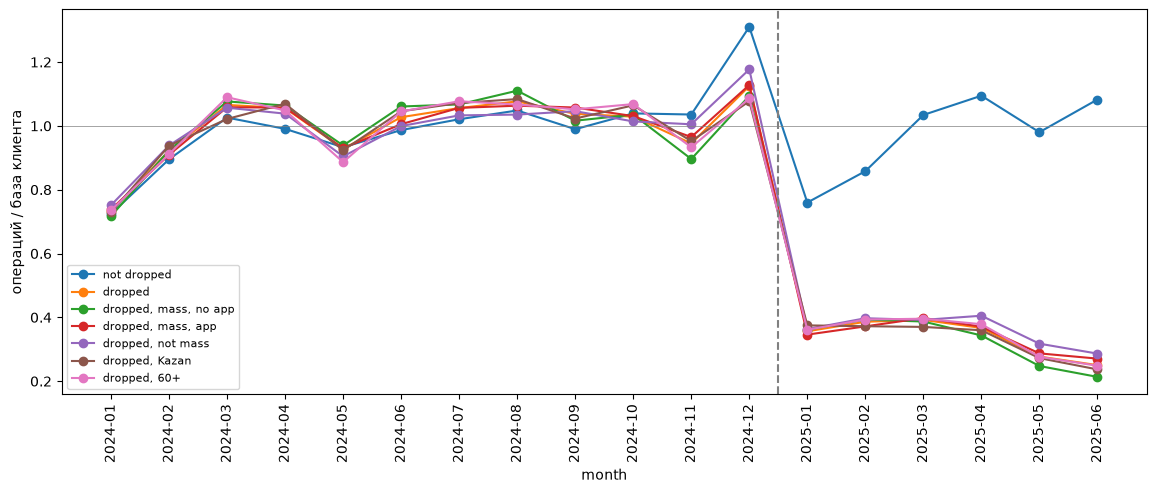

In [78]:
# траектории; пунктир - граница 2024 / 2025
ax = traj.plot(figsize=(14, 5), marker="o")
ax.axvline(11.5, color="gray", ls="--")
ax.axhline(1, color="gray", lw=0.5)
ax.set_xticks(range(len(traj.index)))
ax.set_xticklabels(traj.index, rotation=90)
ax.set_ylabel("операций / база клиента")
ax.legend(fontsize=8)
plt.show()

на графике снизившиеся - одна линия: ступенька в январе 2025 и второе снижение в мае. Т.е. падение не постепенное, а резкое, и к концу периода продолжается

In [79]:
# доля отклоненных и возвратов: база (2024) и 2025, у снизившихся и остальных, %
for name, d in [("dropped", metric["dropped"]), ("not dropped", ~metric["dropped"])]:
    s = txn_f[txn_f["client_id"].isin(metric.index[d])]
    print(name)
    print((pd.crosstab(s["status"], s["month"].dt.year, normalize="columns") * 100).round(2), "\n")

# глубина падения у снизившихся
print(pd.cut(metric.loc[metric["dropped"], "change_all"], bins=[-1.001, -0.8, -0.6, -0.45]).value_counts().sort_index())

dropped
month       2024   2025
status                 
возврат     1.16   1.10
отклонено   1.88   1.95
успешно    96.95  96.95 

not dropped
month       2024   2025
status                 
возврат     1.19   1.21
отклонено   2.07   2.00
успешно    96.74  96.79 

change_all
(-1.001, -0.8]    174
(-0.8, -0.6]      869
(-0.6, -0.45]     465
Name: count, dtype: int64


доля отклоненных почти не изменилась: у снизившихся 1.88% -> 1.95%, у остальных 2.07% -> 2.00%, т.е. карты им не отклоняют - они сами реже платят. Глубина падения: на 80% и больше - 174 из 1508, на 60-80% - 869, на 45-60% - 465

In [80]:
# каждый снизившийся: январь-апрель и май-июнь 2025 относительно своей базы - упал сразу или к концу периода
d12 = metric["dropped"] & full12
early = idx.loc[d12, (idx.columns.year == 2025) & (idx.columns.month <= 4)].mean(axis=1)
late = idx.loc[d12, (idx.columns.year == 2025) & (idx.columns.month >= 5)].mean(axis=1)
bins = [0, 0.2, 0.4, 0.6, 0.8, 100]
print(pd.crosstab(pd.cut(early, bins, include_lowest=True), pd.cut(late, bins, include_lowest=True),
                  rownames=["2025-01..04"], colnames=["2025-05..06"]))

2025-05..06    (-0.001, 0.2]  (0.2, 0.4]  (0.4, 0.6]  (0.6, 0.8]  (0.8, 100.0]
2025-01..04                                                                   
(-0.001, 0.2]             81          29          21          10             2
(0.2, 0.4]               349         200         121          52            15
(0.4, 0.6]               212         135         112          39             3
(0.6, 0.8]                51          25           2           0             0


четких двух групп по времени нет, но к концу периода у многих почти ничего не осталось: в мае-июне 20% базы и меньше у 693 из 1459 снизившихся с полным 2024 (81 + 349 + 212 + 51), почти все они в январе-апреле были на 20-60% базы. Остальные 766 держатся выше 20% базы. Это как раз пример из задания - "активность сошла почти на нет к концу периода", поэтому проверяем, у кого так чаще

In [81]:
# отдельные категории: у скольких клиентов операции в категории упали на 80% и больше (если в базе было хотя бы 1 в месяц)
base_c, eval_c = per_month("category")
cat_drop = (eval_c / base_c - 1 <= -0.8) & (base_c >= 1)
pd.DataFrame({"dropped (of 1508)": cat_drop[metric["dropped"]].sum(),
              "not dropped (of 3521)": cat_drop[~metric["dropped"]].sum()})

,dropped (of 1508),not dropped (of 3521)
category,,
АЗС,70,25
Аптеки,63,20
Кафе и рестораны,106,29
Одежда и обувь,99,23
Онлайн-сервисы,40,19
Продукты,335,20
Развлечения и досуг,87,274
Связь и интернет,56,11
Транспорт,128,31


у снизившихся падение по категориям примерно пропорционально их размеру (больше всего - продукты, 335). А у не снизившихся выделяются развлечения: 274 клиента из 3521 почти перестали платить картой за развлечения, хотя в целом не снизились, в остальных категориях таких 11-31. Это отдельная история - "перестали тратить на развлечения", ее метрика по всем операциям не видит

In [82]:
# у кого из снизившихся к маю-июню почти ничего не осталось (20% базы и меньше), доля по подгруппам
late_zero = (late <= 0.2).reindex(metric.index, fill_value=False)
dm = metric[d12]
for col in ["segment", "has_mobile_app", "city", "age_group", "income_source"]:
    g = late_zero[d12].groupby(dm[col], observed=True).agg(["size", "sum", "mean"])
    g.columns = ["dropped", "late_zero", "late_zero %"]
    g["late_zero %"] = (g["late_zero %"] * 100).round(1)
    print(g, "\n")
print((pd.crosstab(dm["segment"], dm["has_mobile_app"], values=late_zero[d12], aggfunc="mean") * 100).round(1))

             dropped  late_zero  late_zero %
segment                                     
Private           25          7         28.0
Зарплатный       177         76         42.9
Массовый        1139        562         49.3
Премиальный      113         46         40.7 

                dropped  late_zero  late_zero %
has_mobile_app                                 
False               793        427         53.8
True                666        266         39.9 

                 dropped  late_zero  late_zero %
city                                            
Екатеринбург         163         69         42.3
Казань               327        164         50.2
Москва               406        205         50.5
Нижний Новгород      161         72         44.7
Новосибирск          155         70         45.2
Санкт-Петербург      242        112         46.3 

           dropped  late_zero  late_zero %
age_group                                 
<30             20         11         55.0
30-39      

"почти на нет к концу периода" не привязано к одной подгруппе: по городам, возрасту и источнику дохода доля от 42.3% до 55.0% при средних 47.5% (693 из 1459). Заметнее всего разница по приложению: без приложения 53.8%, с приложением 39.9%, у массовых без приложения 55.6%. Т.е. это скорее уточнение для группы "массовые без приложения", чем отдельная группа

In [83]:
# перестали платить за развлечения, но в целом не снизились: кто они (доля в разрезе против всех клиентов в расчете)
ent = cat_drop["Развлечения и досуг"] & ~metric["dropped"]
print(f"entertainment quitters: {ent.sum()}")
for col in ["segment", "has_mobile_app", "city", "age_group", "income_source", "card_type"]:
    t = pd.DataFrame({"quitters %": (metric.loc[ent, col].value_counts(normalize=True) * 100).round(1),
                      "all %": (metric[col].value_counts(normalize=True) * 100).round(1)})
    print(t, "\n")
print(metric.loc[ent, "change_all"].describe().round(3))

entertainment quitters: 274
             quitters %  all %
segment                       
Private            10.6    4.3
Зарплатный         24.2   26.8
Массовый           31.9   53.0
Премиальный        33.3   15.9 

                quitters %  all %
has_mobile_app                   
True                  55.8   60.5
False                 44.2   39.5 

                 quitters %  all %
city                              
Екатеринбург           15.4   12.7
Казань                 13.6   17.2
Москва                 28.6   28.9
Нижний Новгород        12.1   12.0
Новосибирск            12.8   12.1
Санкт-Петербург        17.6   17.1 

           quitters %  all %
age_group                   
40-49            32.8   28.8
50-59            27.4   25.4
60-69            13.9   15.8
30-39            12.4   14.7
70-79             8.8    8.3
80+               3.3    5.4
<30               1.5    1.6 

                         quitters %  all %
income_source                             
Зарплата в друг

274 клиента, почти переставших платить за развлечения, чаще обычного из дорогих сегментов: премиальные 33.3% против 15.9% у всех, Private 10.6% против 4.3%, премиальная карта 15.0% против 8.2%, зарплата в нашем банке 51.5% против 44.4%. По возрасту, городу и приложению почти не отличаются. В целом у них операций меньше умеренно: медиана -0.283, от -0.446 до +0.018 - падение почти целиком за счет развлечений

In [84]:
# Казань: снизившихся больше из-за состава (больше массовых) или внутри каждого сегмента тоже?
kazan = metric["city"] == "Казань"
t = pd.DataFrame({
    "Kazan, n": metric[kazan].groupby("segment", observed=True).size(),
    "Kazan, dropped %": (metric[kazan].groupby("segment", observed=True)["dropped"].mean() * 100).round(1),
    "other cities, n": metric[~kazan].groupby("segment", observed=True).size(),
    "other cities, dropped %": (metric[~kazan].groupby("segment", observed=True)["dropped"].mean() * 100).round(1),
})
t

,"Kazan, n","Kazan, dropped %","other cities, n","other cities, dropped %"
segment,,,,
Private,12,25.0,202,11.9
Зарплатный,64,18.8,1281,14.4
Массовый,747,41.9,1911,44.3
Премиальный,41,9.8,759,15.4


в Казани снизившихся больше только из-за состава: там 747 из 864 клиентов - массовые, а внутри массового сегмента в Казани снизились даже меньше, чем в других городах (41.9% против 44.3%). Отдельного эффекта города нет, Казань группой не делаем

группы (в каждую - только клиенты с согласием на коммуникацию, клиент попадает ровно в одну группу, правила не пересекаются по построению):

| группа | кто | что произошло |
|---|---|---|
| 1. массовые без приложения | массовый сегмент, нет мобильного приложения | с января 2025 операций по карте меньше на 45% и больше, у половины к маю-июню почти ноль |
| 2. массовые с приложением | массовый сегмент, есть приложение | с января 2025 операций по карте меньше на 45% и больше |
| 3. зарплатные, премиальные и Private | не массовый сегмент | с января 2025 операций по карте меньше на 45% и больше |
| 4. ушли из развлечений | в 2024 платили картой за развлечения хотя бы раз в месяц | в 2025 за развлечения почти перестали (меньше на 80% и больше), остальные операции почти на месте (в целом меньше 45%) |

группы 1-3 различаются тем, кто клиент, а не характером падения: у всех снизившихся оно одинаковое (ступенька в январе 2025, все каналы и категории). Массовых делим по приложению, т.к. это главный признак после сегмента (58.8% снизившихся без приложения против 33.7% с ним) и от него зависит канал коммуникации

In [85]:
# группы по правилам
opt = metric["marketing_opt_in"]
mass = metric["segment"] == "Массовый"
non_mass = metric["segment"].isin(["Зарплатный", "Премиальный", "Private"])
app = metric["has_mobile_app"]
ent_quit = cat_drop["Развлечения и досуг"]

metric["group"] = None
metric.loc[opt & metric["dropped"] & mass & ~app, "group"] = "1. массовые без приложения"
metric.loc[opt & metric["dropped"] & mass & app, "group"] = "2. массовые с приложением"
metric.loc[opt & metric["dropped"] & non_mass, "group"] = "3. зарплатные, премиальные и Private"
metric.loc[opt & ~metric["dropped"] & ent_quit, "group"] = "4. ушли из развлечений"

print(metric["group"].value_counts().sort_index())
print(f"total: {metric['group'].notna().sum()} (budget 2000, each group >= 150)")

group
1. массовые без приложения              535
2. массовые с приложением               481
3. зарплатные, премиальные и Private    301
4. ушли из развлечений                  234
Name: count, dtype: int64
total: 1551 (budget 2000, each group >= 150)


4 группы: 535, 481, 301 и 234 клиента, все больше 150, вместе 1551 - в бюджет 2000 укладываемся

In [86]:
# описание групп: медианы (у операций правый хвост, 5.1)
gm = metric[metric["group"].notna()]
desc_g = gm.groupby("group").agg(
    n=("change_all", "size"),
    ops_2024=("base_all", "median"),
    ops_2025=("eval_all", "median"),
    change=("change_all", "median"),
    age=("age", "median"),
)
desc_g["late_zero %"] = (late_zero[gm.index].groupby(gm["group"]).mean() * 100).round(1)
desc_g["entertainment 2024"] = base_c.loc[gm.index, "Развлечения и досуг"].groupby(gm["group"]).median()
desc_g["entertainment 2025"] = eval_c.loc[gm.index, "Развлечения и досуг"].groupby(gm["group"]).median()
desc_g.round(2)

,n,ops_2024,ops_2025,change,age,late_zero %,entertainment 2024,entertainment 2025
group,,,,,,,,
1. массовые без приложения,535,5.00,1.50,-0.67,59.0,54.6,0.25,0.00
2. массовые с приложением,481,5.50,1.83,-0.66,49.0,40.1,0.33,0.00
"3. зарплатные, премиальные и Private",301,6.00,2.17,-0.64,55.0,38.2,0.58,0.17
4. ушли из развлечений,234,8.46,6.17,-0.28,50.0,0.0,2.17,0.17


медианы по группам:
- 1, массовые без приложения: 5.00 операций в месяц в 2024 -> 1.50 в 2025 (-0.67), самые возрастные (медиана 59 лет), к маю-июню почти ноль у 54.6% (здесь и дальше - доля от всей группы, считается только у клиентов с полным 2024)
- 2, массовые с приложением: 5.50 -> 1.83 (-0.66), 49 лет, почти ноль к лету у 40.1%
- 3, зарплатные, премиальные и Private: 6.00 -> 2.17 (-0.64), 55 лет, 38.2%
- 4, ушли из развлечений: самые активные - 8.46 -> 6.17 (-0.28), 50 лет; за развлечения 2.17 операции в месяц -> 0.17

за счет чего упало: у групп 1-3 падение равномерное - все каналы и категории сразу, с января 2025, доля отклоненных не выросла (карты работают). В данных нет прямой причины, но картина похожа на перенос трат на карту другого банка: снизившихся больше среди тех, у кого зарплата в другом банке или не указана (34.2% и 37.5% против 22.6%). У группы 1 дополнительно нет приложения и возраст старше - им сложнее пользоваться картой без приложения (оплата телефоном, переводы). У группы 4 упали только развлечения - падение конкретной категории, остальные траты на месте

In [87]:
# устойчивость к порогу: размеры групп при пороге -0.4, -0.45, -0.5
for thr in [-0.4, -0.45, -0.5]:
    d = metric["change_all"] <= thr
    sizes = pd.Series({
        "1": (opt & d & mass & ~app).sum(),
        "2": (opt & d & mass & app).sum(),
        "3": (opt & d & non_mass).sum(),
        "4": (opt & ~d & ent_quit).sum(),
    })
    print(f"threshold {thr}: {sizes.to_dict()} | total {sizes.sum()}")

threshold -0.4: {'1': 571, '2': 517, '3': 349, '4': 207} | total 1644
threshold -0.45: {'1': 535, '2': 481, '3': 301, '4': 234} | total 1551
threshold -0.5: {'1': 509, '2': 446, '3': 260, '4': 250} | total 1465


при пороге -0.4 и -0.5 правила те же, меняются только размеры: группа 1 от 509 до 571, 2 - от 446 до 517, 3 - от 260 до 349, 4 - от 207 до 250, всего от 1465 до 1644. Все группы больше 150, бюджет 2000 не превышен, т.е. выбор порога по провалу выводы не меняет

### 7.1. Кого в кампанию не берём и почему

In [88]:
# кого не берем и почему - разбивка всех 5612 клиентов, в сумме должно сойтись
in_camp = metric["group"].notna()
dr = metric["dropped"]
rows = {
    "in campaign (groups 1-4)": in_camp.sum(),
    "card since 2024-10": (m["base_months"] < 3).sum(),
    "dropped, no consent": (dr & ~opt).sum(),
    "dropped, consent, segment unknown": (dr & opt & metric["segment"].isna()).sum(),
    "quit entertainment, no consent": (~dr & ent_quit & ~opt).sum(),
    "not dropped, not quit entertainment": (~dr & ~ent_quit).sum(),
}
breakdown = pd.Series(rows, name="clients")
print(breakdown)
print(f"total: {breakdown.sum()} of {clients.shape[0]}")
print(f"no reliable base, of them without any operations: {(~clients['client_id'].isin(txn_f['client_id'])).sum()}")
print("plus 388 client_id not in clients - left the bank (3.5)")

in campaign (groups 1-4)               1551
card since 2024-10                      583
dropped, no consent                     186
dropped, consent, segment unknown         5
quit entertainment, no consent           40
not dropped, not quit entertainment    3247
Name: clients, dtype: int64
total: 5612 of 5612
no reliable base, of them without any operations: 7
plus 388 client_id not in clients - left the bank (3.5)


в кампанию идут 1551 клиент, у всех есть согласие на коммуникацию - это условие каждого правила. Все 5612 клиентов раскладываются так (сумма сходится, см. выше):
- 1551 - в кампании
- 583 - карта открыта с 2024-10: меньше 3 полных месяцев карты в 2024, надежной базы нет, снижение не посчитать (6); среди них 7 клиентов вообще без операций
- 186 - снизились, но нет согласия на коммуникацию - связаться нельзя
- 5 - снизились, согласие есть, но сегмент неизвестен (NaN после конфликта дублей, 3.2) - ни под одно правило не подходят
- 40 - ушли из развлечений, но нет согласия
- 3247 - не снизились и не ушли из развлечений - им кампания не нужна

отдельно - 388 ушедших клиентов: их операции есть, но в справочнике действующих на 30.06.2025 их нет (последние операции до 2025-04, 3.5), нет признаков и согласия

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

| гипотеза | что проверили | результат |
|---|---|---|
| в Казани особая проблема | снизившихся в Казани 38.5% против 29.986% в среднем | не подтвердилось: это состав - в Казани больше массовых, а внутри массового сегмента в Казани снизились 41.9% против 44.3% в других городах |
| клиенты перешли с карты на оплату телефоном | у снизившихся токен упал на 62.7%, как и остальные каналы | не подтвердилось: токен растет (+64.6%) только у тех, кто не снизился |
| картам стали чаще отказывать | доля отклоненных у снизившихся 1.88% в 2024 и 1.95% в 2025 | не подтвердилось: доля не изменилась |
| к концу периода почти до нуля дошла отдельная подгруппа | доля "почти ноль в мае-июне" по городам, возрасту и доходу | не подтвердилось: от 42.3% до 55.0% при средних 47.5%, только у клиентов без приложения заметно выше (53.8% против 39.9%) |
| возвраты меняют выводы | метрика с возвратами и без | не подтвердилось: Спирмен 0.998, медиана -0.210 и -0.208 |

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [89]:
# итоговый список: клиенты в группах (6, 7)
campaign = metric.loc[metric["group"].notna(), ["group"]].reset_index()

# очищенная таблица для отчета: все 5612 клиентов с признаками, базой и 2025 (6), изменением, группой и развлечениями (7)
# у клиентов без надежной базы (base_months < 3) изменения и группы нет
ent = pd.DataFrame({"ent_2024": base_c["Развлечения и досуг"], "ent_2025": eval_c["Развлечения и досуг"]})
clean = m[["base_months"]].join(clients.set_index("client_id"))
clean = clean.join(metric[["base_all", "eval_all", "base_nr", "eval_nr", "change_all", "change_nr", "dropped", "age_group", "group"]]).join(ent)
clean["dropped"] = clean["dropped"].astype("boolean")
clean = clean.reset_index()

# операции за период клиентов из справочника 
txn_clean = txn_f.drop(columns="month")

clean.to_parquet("data/clean_data.parquet", index=False)
txn_clean.to_parquet("data/txn_clean.parquet", index=False)
cleaning_log.to_csv("data/cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("data/campaign_list.csv", index=False, encoding="utf-8")

print(f"clean: {clean.shape} | txn_clean: {txn_clean.shape} | cleaning_log: {cleaning_log.shape} | campaign: {campaign.shape}, client_id unique: {campaign['client_id'].is_unique}")

clean: (5612, 32) | txn_clean: (584771, 11) | cleaning_log: (19, 8) | campaign: (1551, 2), client_id unique: True
